In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
import os

# Data Ingest

In [46]:
def get_data(path, total_channels):

    start_time_line = 7
    measurement_time_line = 9
    data_start_line = 12
    data_end_line = 12 + total_channels


    in_file = open(path, "r")

    lines = in_file.readlines()

    start = lines[start_time_line].strip().split(" ")
    start_date, start_time = start[0], start[1]

    measurement_time = lines[measurement_time_line].strip().split(" ")
    live_time, real_time  = measurement_time[0], measurement_time[1]

    data = lines[data_start_line:data_end_line + 1]

    data_dict = {
        "start_date": start_date,
        "start_time": start_time,
        "live_time": float(live_time),
        "real_time": float(real_time),
        "dead_time": float(np.divide(np.subtract(float(real_time),float(live_time)),float(real_time)) * 100),
        "data": [int(x.strip()) for x in data]
    }

    in_file.close()

    return data_dict


# Data Paths and Global Variables

In [47]:
mu = "\u03bc"

TOTAL_CHANNELS = 8192 - 1
TOTAL_CHANNELS_2 = 512-1

# T_DELAY_US = 0.28
T_DELAY_US = 0.800

data_folder_path = r"G:\My Drive\ADVLAB\Muon-Lifetime\Data"

# data_path = data_folder_path + r"/MuonTest.Spe"
# data_path = data_folder_path + r"/MuonTest2.Spe"
# data_path = data_folder_path + r"/MuonTest3.Spe"
# data_path = data_folder_path + r"/MuonTest4.Spe"
# data_path = data_folder_path + r"/MuonTest6.1.Spe"
data_path = data_folder_path + r"/MuonTest6.2.Spe"

time_cal_path_1 = data_folder_path + r"/timeCal_P0128_R2048.Spe"
time_cal_path_2 = data_folder_path + r"/timeCal512_P0128_P2048.Spe"

hourly_folder_path = data_folder_path + r"/MuonCounts/run1"
# hourly_folder_path = data_folder_path + r"/MuonCounts/run2"



# Data Rebinning

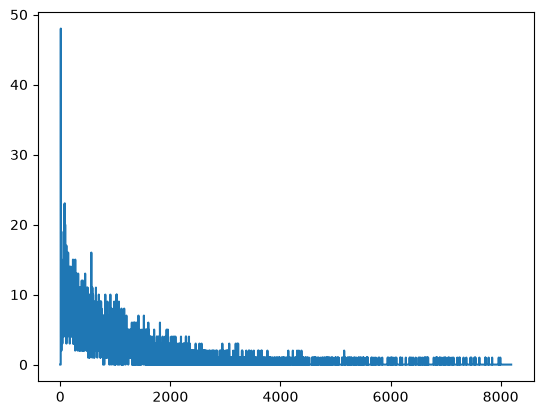

In [48]:
data_dict = get_data(data_path, TOTAL_CHANNELS)
plt.plot(data_dict["data"])
plt.show()

In [49]:
# Bin counts the caller can choose from (2**9 ... 2**14).
ALLOWED_BINS = (512, 1024, 2048, 4096, 8192, 16384)

def rebin_histogram(counts, n_bins):
    """
    Rebin a histogram to `n_bins` channels, conserving the total counts.
    """
    counts = np.asarray(counts)

    n_bins = int(n_bins)

    n_in = counts.size  # number of channels in the given data

    if n_in % n_bins == 0:
        # Whole number of old channels per new bin: sum each block.
        return counts.reshape(n_bins, n_in // n_bins).sum(axis=1)

    # General case: treat each channel's counts as spread evenly across it
    # and integrate that over the new bin edges.
    old_edges = np.arange(n_in + 1)
    new_edges = np.linspace(0, n_in, n_bins + 1)
    cumulative = np.concatenate(([0.0], np.cumsum(counts, dtype=float)))
    return np.diff(np.interp(new_edges, old_edges, cumulative))

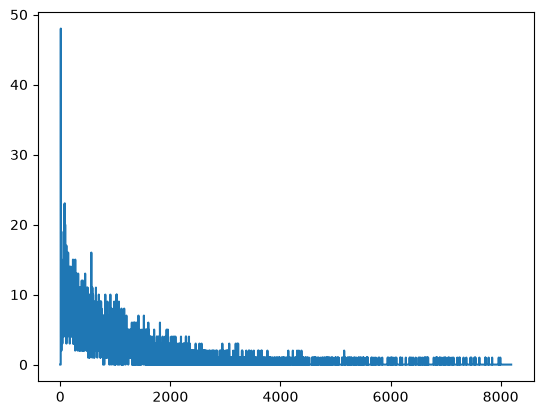

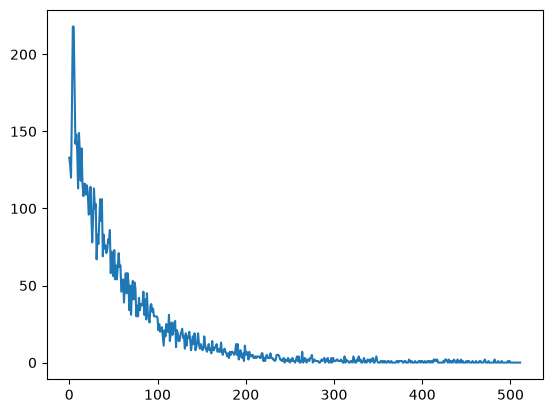

In [50]:
plt.plot(data_dict['data'])
plt.show()

copy_data = data_dict['data'].copy()
rebinned_data = rebin_histogram(copy_data, 512)

rebinned_data_dict = data_dict.copy()
rebinned_data_dict['data'] = rebinned_data

plt.plot(rebinned_data)
plt.show()

# Time Calibration

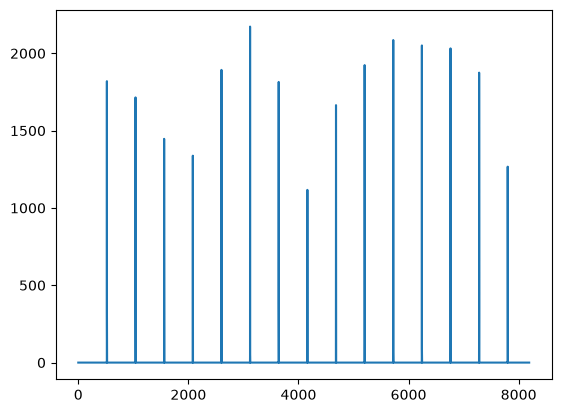

In [51]:
time_cal_1 = get_data(time_cal_path_1, TOTAL_CHANNELS)
plt.plot(time_cal_1["data"])
plt.show()

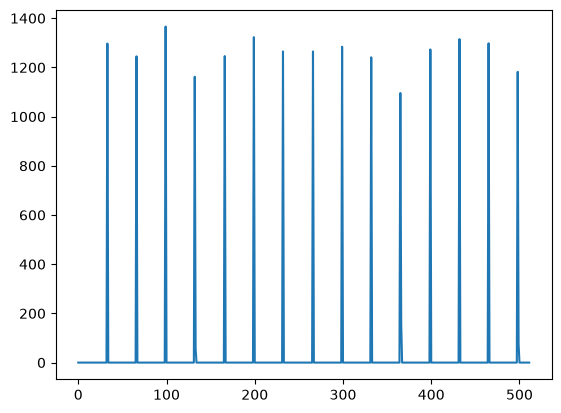

In [52]:
time_cal_2 = get_data(time_cal_path_2, TOTAL_CHANNELS_2)
plt.plot(time_cal_2["data"])
plt.show()

In [53]:
def get_time_cal(data_dict, time_cal_dict, period, degree):

  # convert data and time_cal to numpy arrays
  time_cal = np.array(time_cal_dict["data"])

  # keep only the tallest channel within +-10 channels of each peak
  original = time_cal.copy()   # compare against untouched counts
  for i in range(len(original)):
    if original[i] > 0:
      lo, hi = max(i - 10, 0), min(i + 11, len(original))
      if i != lo + np.argmax(original[lo:hi]):
        time_cal[i] = 0

  # assign 1 to any element that is non zero
  binary_peaks = np.zeros_like(time_cal)
  binary_peaks[time_cal > 0] = 1

  # # the first peak should be 2
  # binary_peaks[np.where(binary_peaks >0 )[0][0]] = 2

  # set each non zero entry to the sum of all before it
  cumulative_peaks = np.cumulative_sum(binary_peaks)
  step_array = cumulative_peaks.astype(np.float64)

  # set regions that are not peaks in raw calibration data to 0.0
  step_array[binary_peaks == 0] = 0.0

  # multiply all nonzero entries by the calibration period
  step_array *= period

  # get just the peaks and their indexes to fit
  peak_indexes = np.where(step_array > 0)[0]
  step_array = step_array[peak_indexes]

  # fit the steps by channel using polyfit
  fit_steps, cov = np.polyfit(peak_indexes, step_array, degree, cov=True)

  # print(np.sqrt(cov[0, 0]))

  return fit_steps, step_array, binary_peaks


In [54]:
def get_time_from_channel_linear(channel, fit_steps):
  return fit_steps[0] * channel + fit_steps[1]

In [55]:
def get_channel_from_time_linear(time, fit_steps):
  return int(np.divide(time - fit_steps[1], fit_steps[0]).round())

In [56]:
def get_time_fit(dict_data, time_cal_dict, show_plot = False):

  time_fit_param, step_array, binary_peaks = get_time_cal(dict_data, time_cal_dict, period = 1.28, degree = 1)
  peak_channels = np.where(binary_peaks > 0)[0]

  time_fit = get_time_from_channel_linear(peak_channels, time_fit_param)

  if show_plot:
    plt.plot(binary_peaks)
    plt.show()

    plt.scatter(peak_channels, step_array, marker = 'o')
    plt.plot(peak_channels, time_fit )
    plt.xlabel("Channel")
    plt.ylabel(f"Time ({mu}s)")
    plt.annotate( f"t = {time_fit_param[0] : .4f} * x - {abs(time_fit_param[1]): .4f}", (max(peak_channels)*.2, 15.5), fontsize=11) # top left annotate the fit equation
    plt.show()

  return time_fit_param

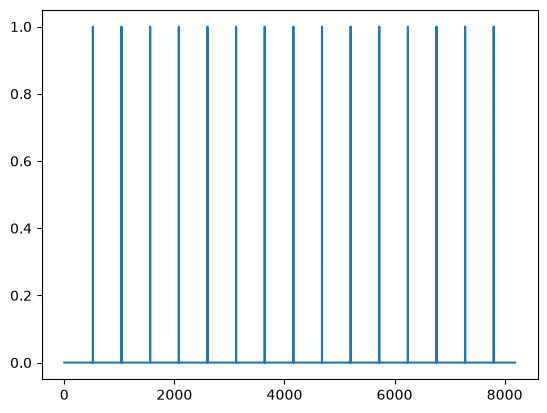

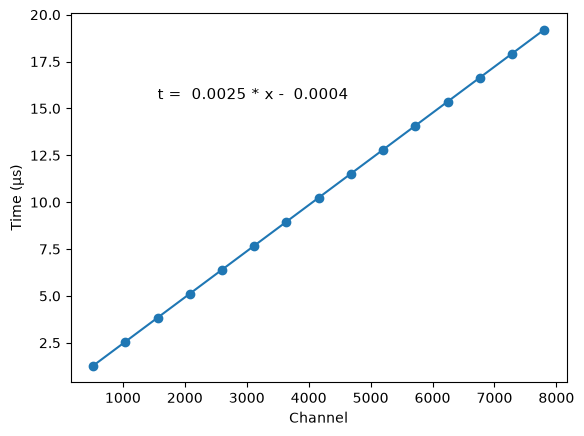

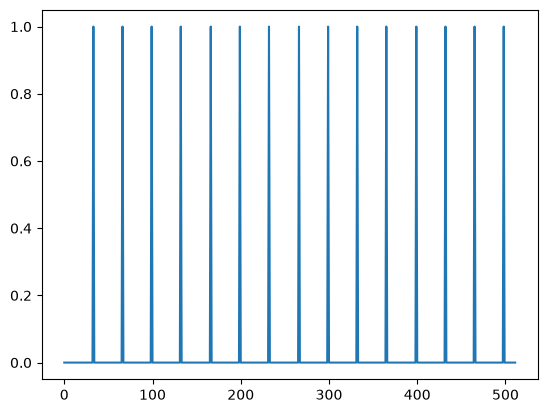

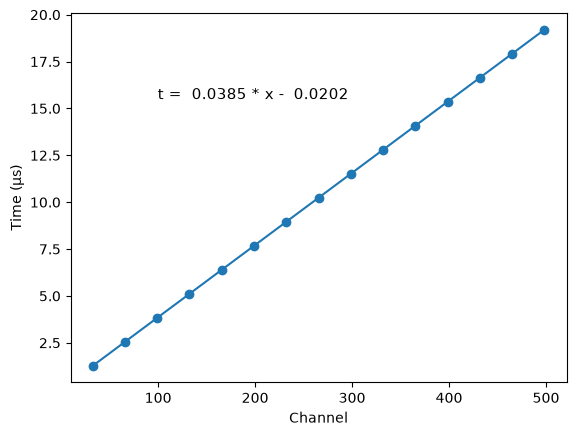

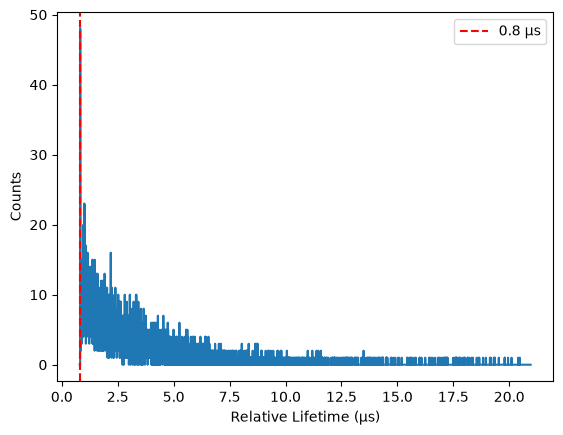

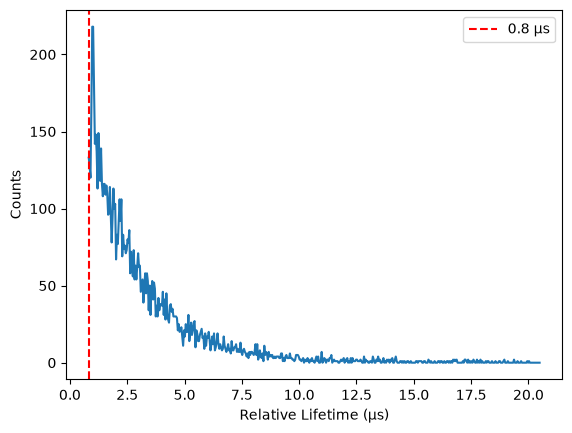

In [57]:
time_fit_param = get_time_fit(data_dict, time_cal_1, show_plot = True)
time_fit_param_512 = get_time_fit(rebinned_data_dict, time_cal_2, show_plot = True)


# plot the data vs time
channel_range = np.arange(len(data_dict["data"]))
channel_range_512 = np.arange(len(rebinned_data_dict["data"]))

time_range = get_time_from_channel_linear(channel_range, time_fit_param)
time_range_512 = get_time_from_channel_linear(channel_range_512, time_fit_param_512)

time_range_delayed = time_range + T_DELAY_US
time_range_512_delayed = time_range_512 + T_DELAY_US


plt.plot(time_range_delayed, data_dict["data"] )
plt.xlabel(f"Relative Lifetime ({mu}s)")
plt.ylabel("Counts")
plt.axvline(time_range_delayed[0], color='r', linestyle='--', label = f"0.8 {mu}s")
plt.legend()
plt.show()

plt.plot(time_range_512_delayed, rebinned_data_dict["data"] )
plt.xlabel(f"Relative Lifetime ({mu}s)")
plt.ylabel("Counts")
plt.axvline(time_range_512_delayed[0], color='r', linestyle='--', label = f"0.8 {mu}s")
plt.legend()
plt.show()

# Data Fitting

In [58]:
def fit_exp_dist_w_oxy_Si(data, start_channel, end_channel, time_fit_parameters, bw,
                          r_O=0.26, r_Si=0.19, r_Na=0.0, r_K=0.0,
                          t_delay=None, linear_bkg=False, verbose=True):
    """
    Poisson-weighted (IRLS) fit of the decay-time spectrum.

    Expected counts per bin:
        [ N_0 * (   e^(-t/tau)            mu+ (tau is free)
                  + r_O  e^(-t/1.795)     mu- bound to O
                  + r_Si e^(-t/0.756)     mu- bound to Si
                  + r_Na e^(-t/1.204)     mu- bound to Na (off by default)
                  + r_K  e^(-t/0.435) )   mu- bound to K  (off by default)
          + background ] * bw

    t = time after the muon = TAC time + t_delay (t_delay defaults to T_DELAY_US).
    Background is flat (C), or C + D*(t - t_mid) if linear_bkg=True.
    Returns: fit_y_data, N_0, tau, C, tau_err
    """
    if t_delay is None:
        t_delay = T_DELAY_US

    x_data = np.arange(start_channel, end_channel + 1)
    x_time = get_time_from_channel_linear(x_data, time_fit_parameters) + t_delay
    y_data = np.asarray(data[start_channel: end_channel + 1], dtype=float)

    def decay_shape(t, tau):
        return (np.exp(-t/tau) + r_O*np.exp(-t/1.795) + r_Si*np.exp(-t/0.756)
                + r_Na*np.exp(-t/1.204) + r_K*np.exp(-t/0.435))

    t_mid = x_time.mean()
    if linear_bkg:
        def model(t, N_0, tau, C, D):
            return (N_0*decay_shape(t, tau) + C + D*(t - t_mid)) * bw
    else:
        def model(t, N_0, tau, C):
            return (N_0*decay_shape(t, tau) + C) * bw

    ############## iteratively reweighted least squares (IRLS) ##############

    p0 = [max(y_data[:20].mean(), 1)/bw*np.exp(x_time[0]/2.2),   # rate scaled back to t = 0
          2.2, max(y_data[-200:].mean()/bw, 0.1)]
    lo, hi = [0, 0.5, 0], [np.inf, 5.0, np.inf]                  # N_0 >= 0, 0.5 < tau < 5, C >= 0
    if linear_bkg:
        p0.append(0.0); lo.append(-np.inf); hi.append(np.inf)    # background slope D, free

    # Step 0: rough weights from the data, just to get a starting point
    p = opt.curve_fit(model, x_time, y_data, p0=p0,
                      sigma=np.sqrt(np.maximum(y_data, 1)), bounds=(lo, hi))[0]

    # Steps 1+: weights from the model, refit until stable
    for i in range(10):
        sigma = np.sqrt(np.maximum(model(x_time, *p), 1e-6))   # sqrt of expected counts; floor avoids /0
        p_new, cov = opt.curve_fit(model, x_time, y_data, p0=p, sigma=sigma,
                                   absolute_sigma=True, bounds=(lo, hi))
        err = np.sqrt(np.diag(cov))
        converged = np.all(np.abs(p_new - p) < 1e-4*err)        # change much smaller than the error
        p = p_new
        if converged:
            break

    fit_N_0, fit_tau, fit_C = p[0], p[1], p[2]
    tau_err = err[1]
    fit_y_data = model(x_time, *p)
    redux_chi2 = np.sum((y_data - fit_y_data)**2 / fit_y_data) / (len(y_data) - len(p))

    if verbose:
        print(f"tau error: {tau_err}")
        print(f"reduced chi squared: {redux_chi2}")

    return fit_y_data, fit_N_0, fit_tau, fit_C, tau_err

tau error: 0.032393321028038664
reduced chi squared: 1.219508958986929
2.2527965101063843


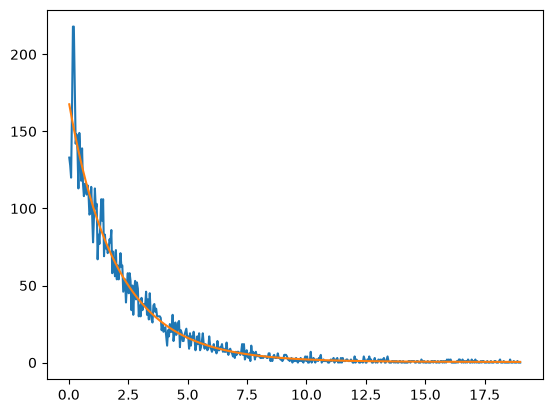

tau error: 0.03259454268481273
reduced chi squared: 1.188158354932472
2.2265086913065417


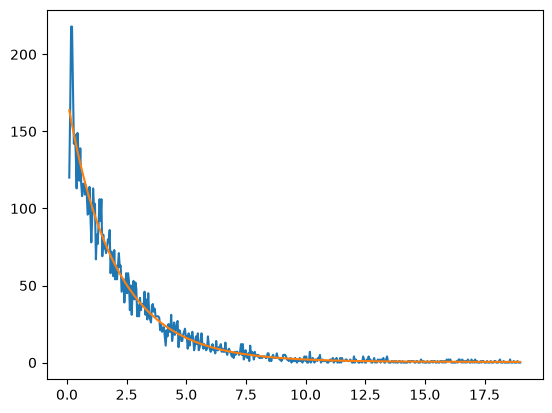

tau error: 0.0337155033170978
reduced chi squared: 1.1234574353181965
2.233887784226084


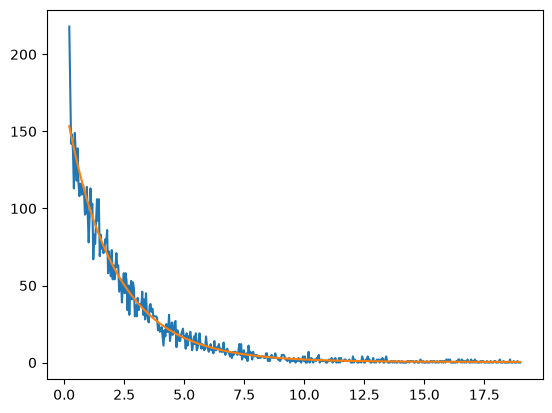

tau error: 0.03541221450079737
reduced chi squared: 1.0598110388172088
2.271520467762019


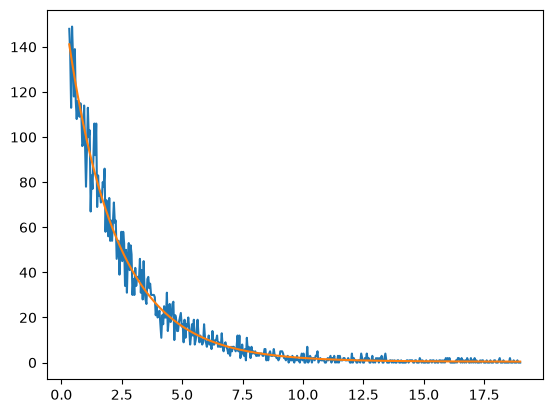

tau error: 0.03616587992164134
reduced chi squared: 1.063545267740203
2.2739917148057867


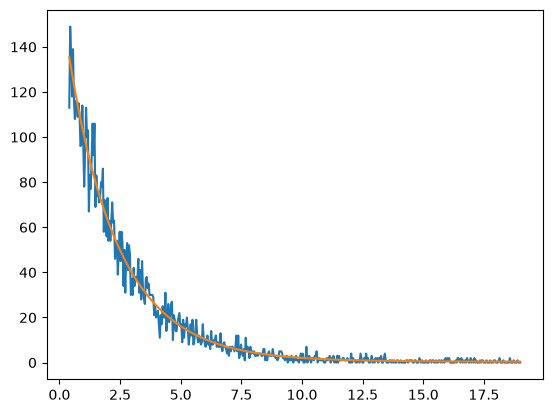

tau error: 0.037249024746768944
reduced chi squared: 1.0578197981442536
2.2733454308627525


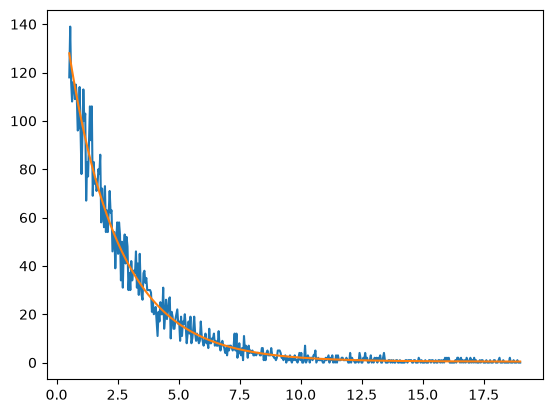

tau error: 0.03803277350244844
reduced chi squared: 1.0576424658842278
2.2749897747048506


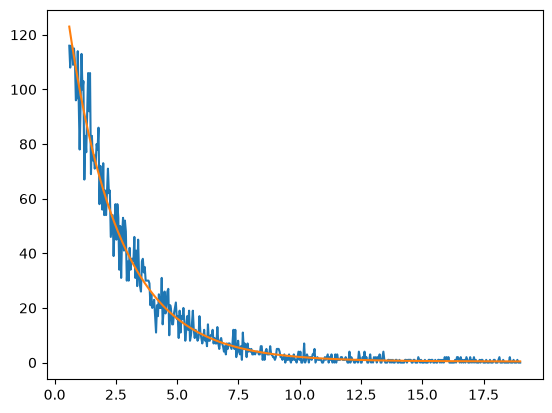

tau error: 0.03895743358650707
reduced chi squared: 1.059893178818069
2.2632549556098547


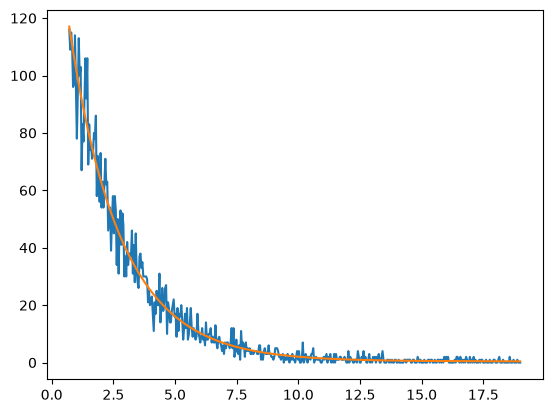

tau error: 0.04010365348393812
reduced chi squared: 1.0658039607714316
2.2606625898587605


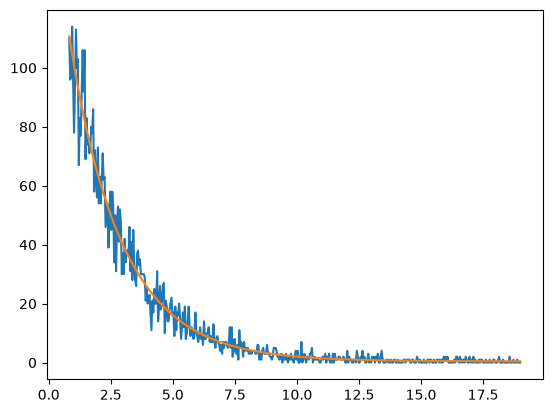

tau error: 0.040764730680336835
reduced chi squared: 1.0667618556884841
2.252967456383041


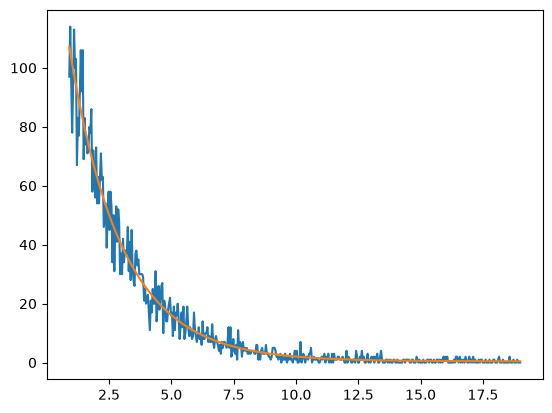

tau error: 0.0419211380003352
reduced chi squared: 1.0686308460208476
2.247650764436991


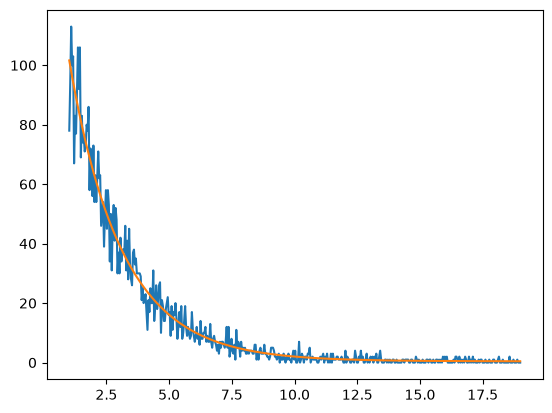

tau error: 0.04238589181551512
reduced chi squared: 1.0592859826170258
2.2288842386412178


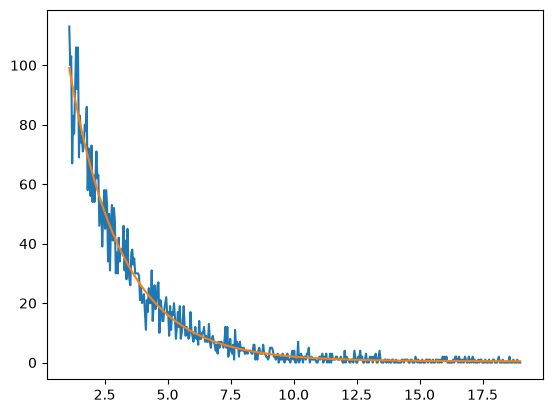

tau error: 0.04410173187205423
reduced chi squared: 1.0604146830870058
2.2456045323140863


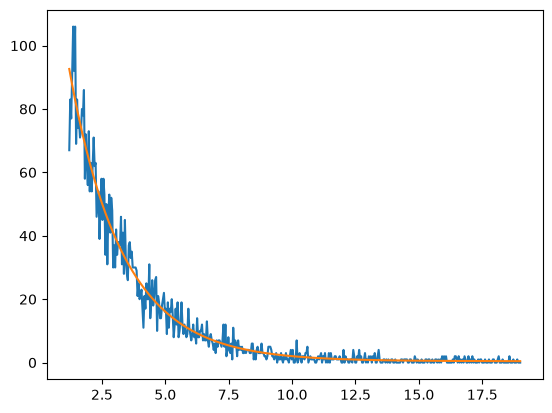

tau error: 0.0447371651473952
reduced chi squared: 1.043711386422155
2.2122675756096917


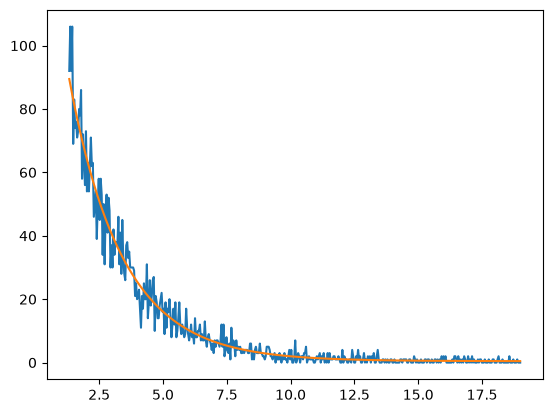

tau error: 0.04604895413727278
reduced chi squared: 1.0397439983407528
2.2276102846136827


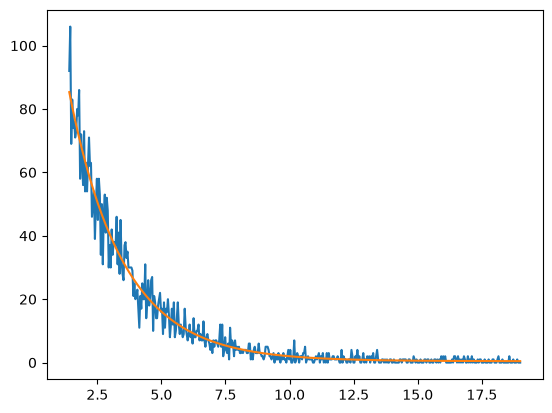

tau error: 0.0478388096711195
reduced chi squared: 1.0275961890511744
2.240575972559909


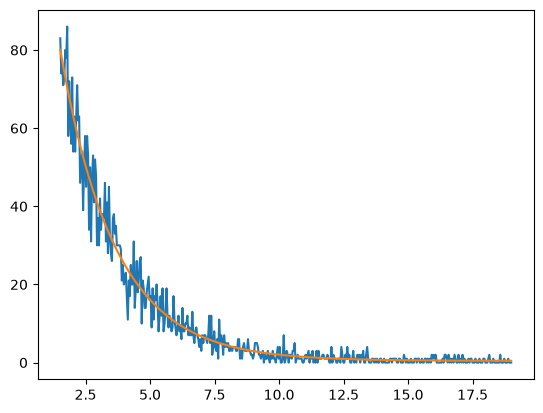

tau error: 0.0488230342908211
reduced chi squared: 1.0312958424606036
2.239266866635324


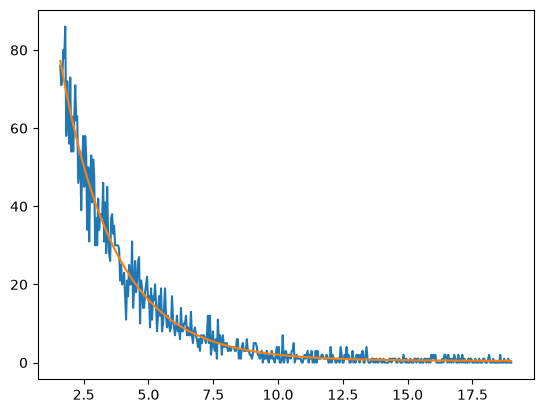

tau error: 0.05022477917186685
reduced chi squared: 1.0372181812859116
2.232594290917261


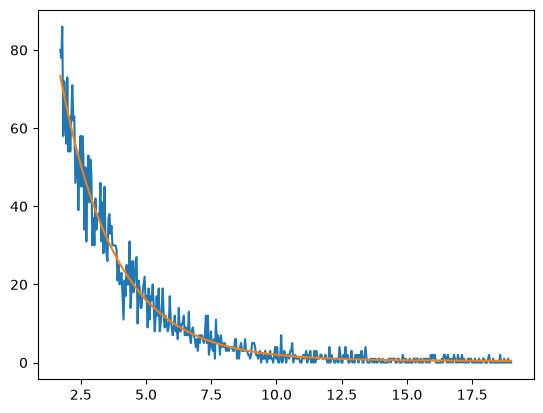

tau error: 0.052565702047389744
reduced chi squared: 1.0338276414076215
2.259082857354137


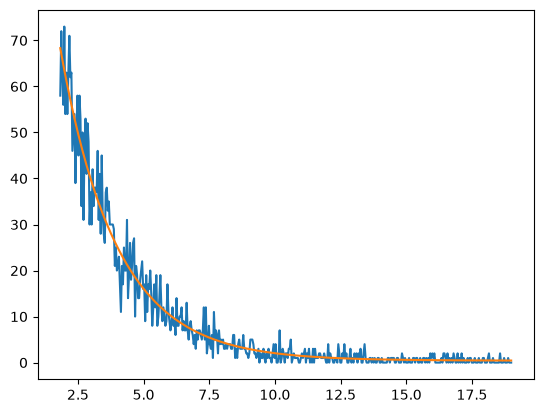

tau error: 0.05353873321025368
reduced chi squared: 1.034023210768688
2.253567669721391


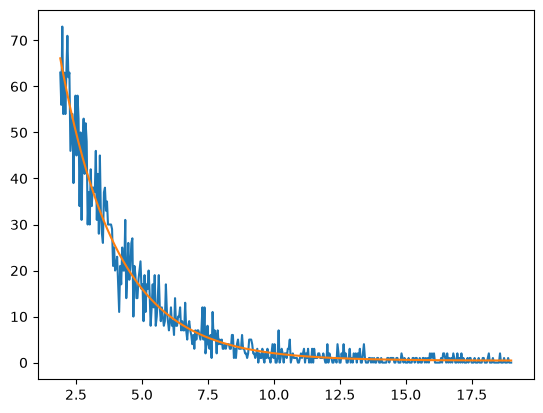

tau error: 0.05518772048888595
reduced chi squared: 1.0348508150251445
2.250354010913169


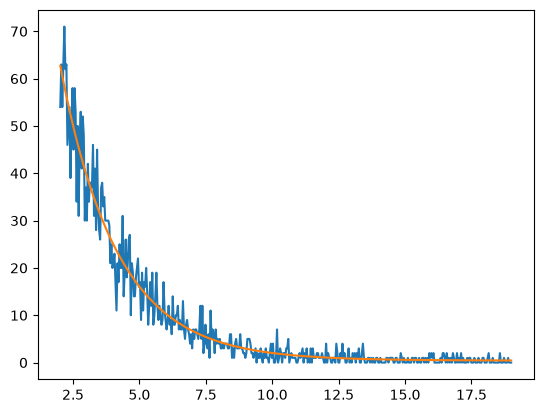

tau error: 0.05614579692626705
reduced chi squared: 1.0364750820441373
2.2422044913747965


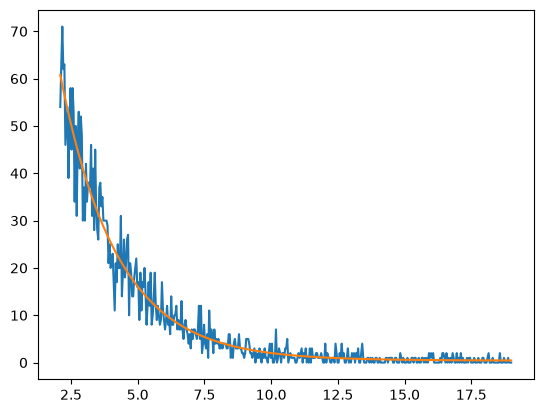

tau error: 0.058295864533683975
reduced chi squared: 1.0355842804824638
2.252204007675841


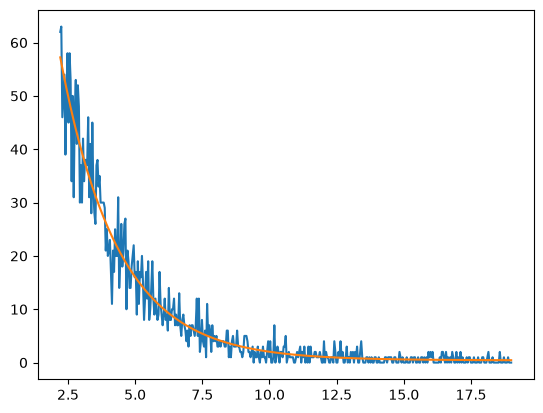

tau error: 0.060008754051430205
reduced chi squared: 1.03766356736956
2.266342566272405


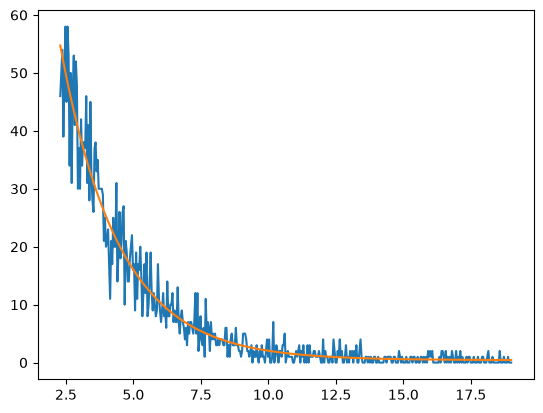

tau error: 0.061494573960725205
reduced chi squared: 1.0403831689200338
2.25117237650026


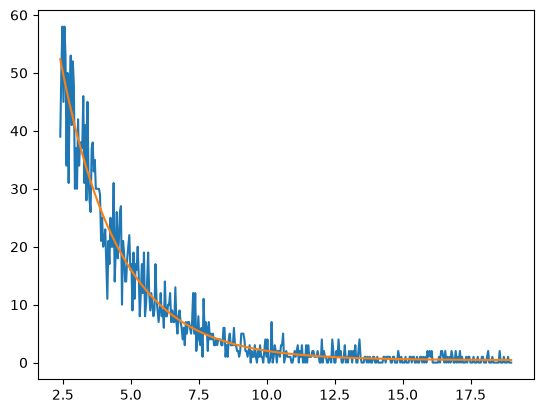

tau error: 0.06318925699270889
reduced chi squared: 1.0366951334201144
2.240428961448736


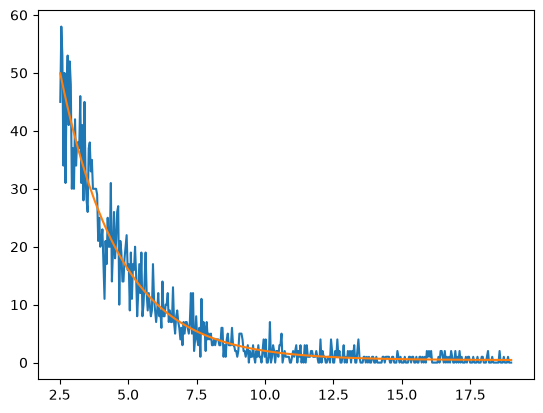

tau error: 0.06478206911035213
reduced chi squared: 1.036692221823345
2.2460280999913422


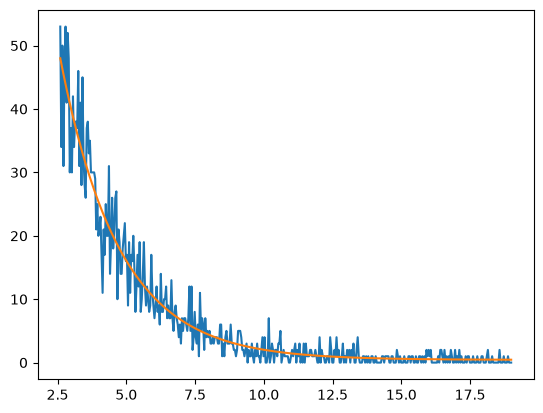

tau error: 0.06671456412889472
reduced chi squared: 1.03324016121995
2.2391430453070376


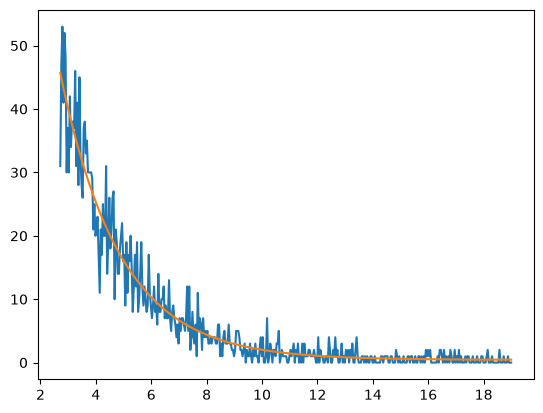

tau error: 0.06749976117961172
reduced chi squared: 1.025958199891054
2.2189128513415817


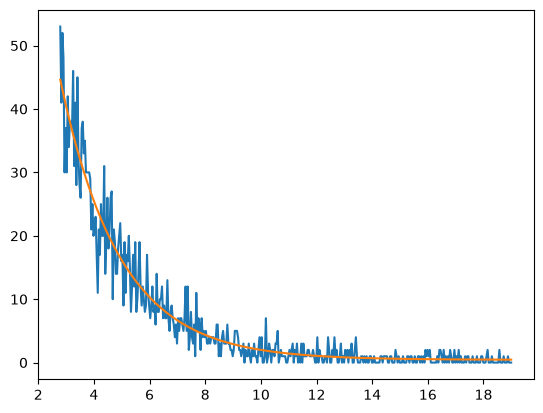

tau error: 0.07071131185845553
reduced chi squared: 1.0245153743815125
2.2438142802747434


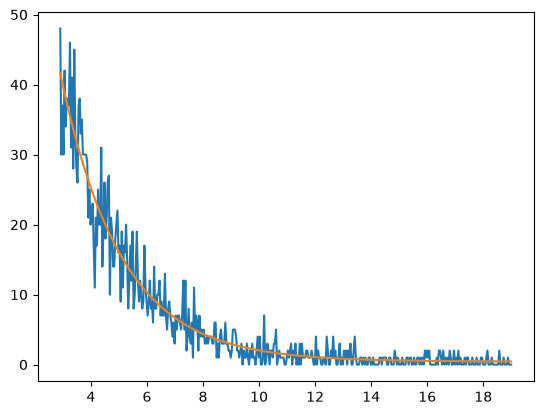

tau error: 0.0725861661331923
reduced chi squared: 1.0215679834176727
2.2299561312369103


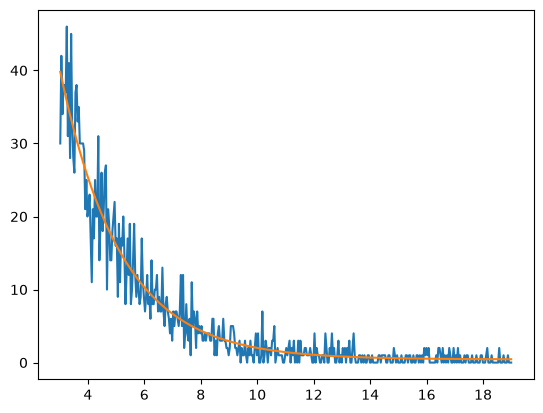

tau error: 0.07373232032323802
reduced chi squared: 1.0198337084975593
2.216693154370184


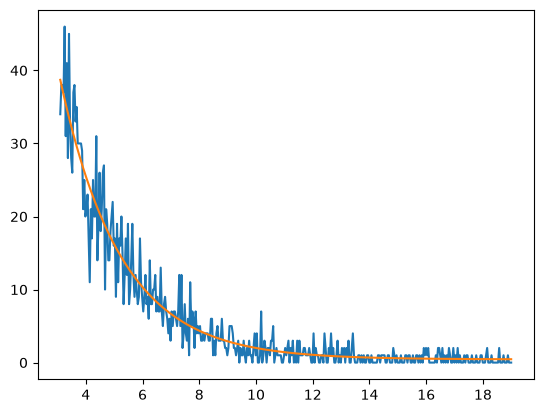

tau error: 0.07595820756110014
reduced chi squared: 1.0257233453284837
2.208211267878723


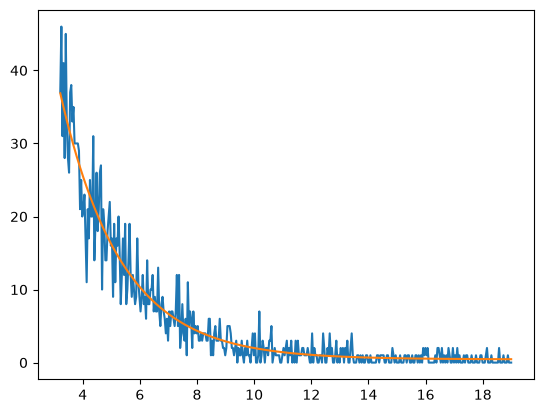

tau error: 0.07855368477477911
reduced chi squared: 1.0243079358549432
2.2287634381189907


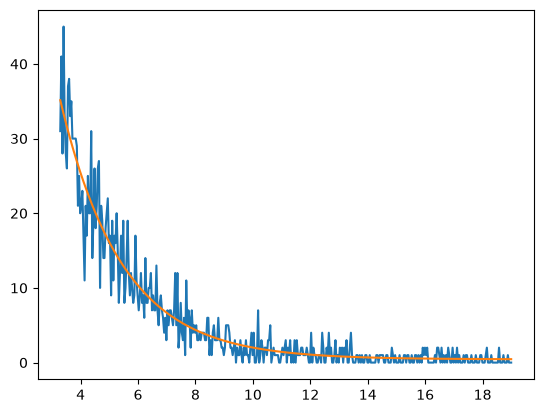

tau error: 0.08094902593131621
reduced chi squared: 1.0249693282288583
2.2207441064541866


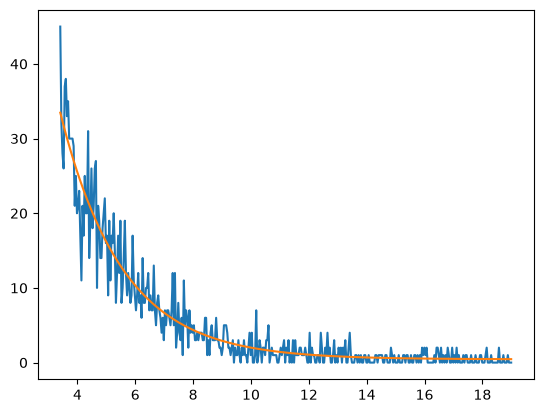

tau error: 0.08449381524137156
reduced chi squared: 1.0212641831243485
2.236925442230991


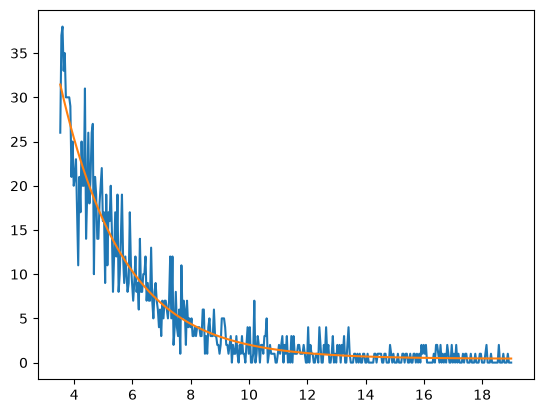

tau error: 0.08652638951930597
reduced chi squared: 1.0210336640276847
2.238273504080403


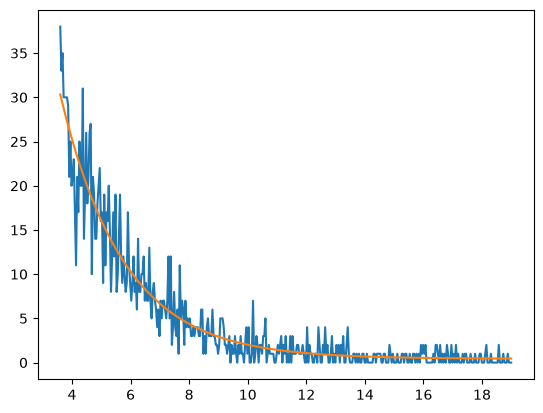

tau error: 0.09180968246037666
reduced chi squared: 1.019695945245406
2.283935669941096


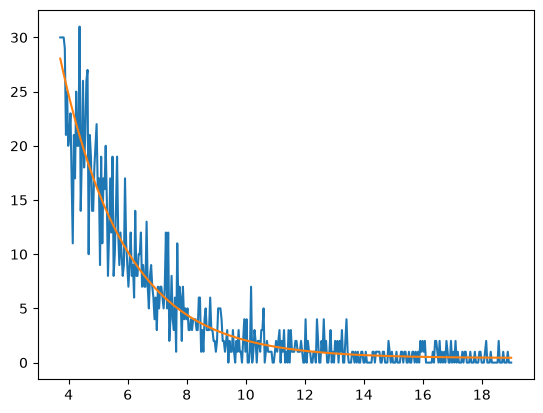

tau error: 0.09459358907692514
reduced chi squared: 1.024128056722431
2.2965647381400234


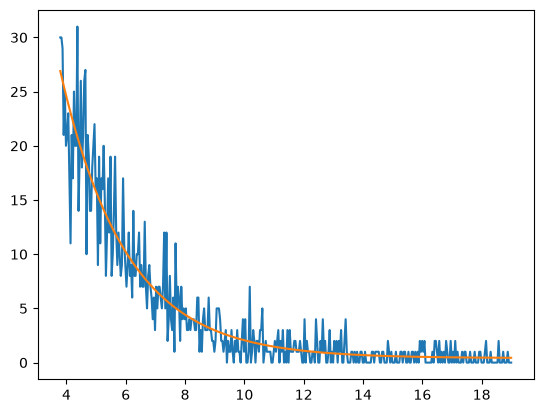

tau error: 0.09957598140519767
reduced chi squared: 1.0291467452027967
2.326889767701145


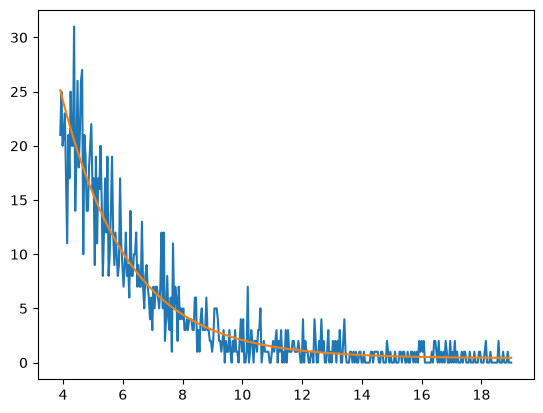

tau error: 0.10148086106181389
reduced chi squared: 1.032486051062798
2.2996091584374008


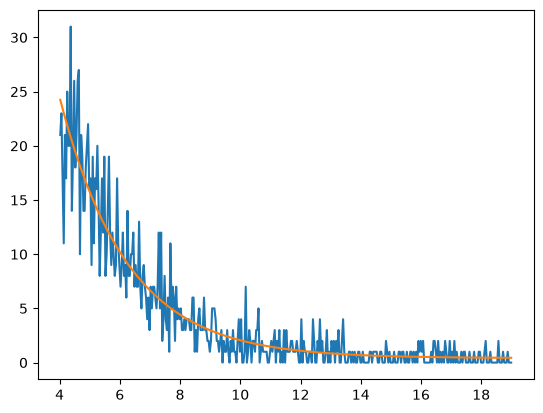

tau error: 0.10304655939241765
reduced chi squared: 1.0362325891321476
2.2855774921711713


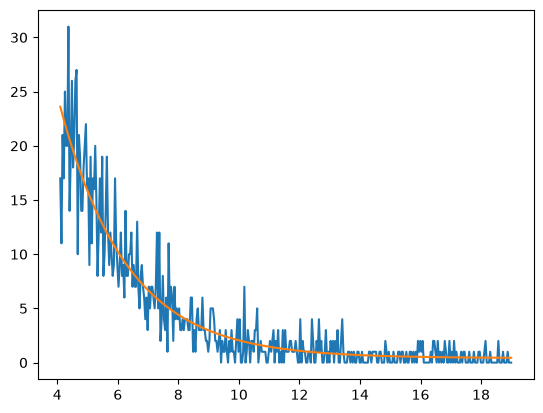

tau error: 0.10247531742782673
reduced chi squared: 1.019072788104162
2.210737999284621


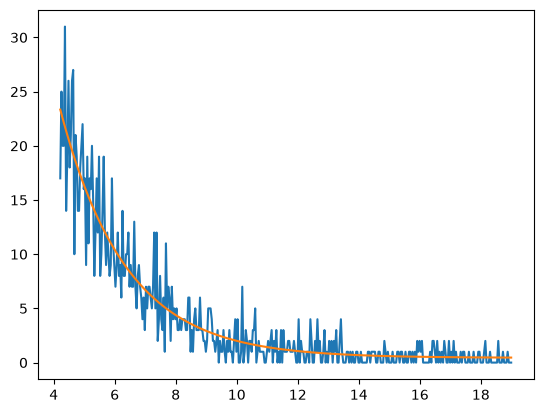

tau error: 0.10408902264920475
reduced chi squared: 1.0191191253959546
2.194739793817549


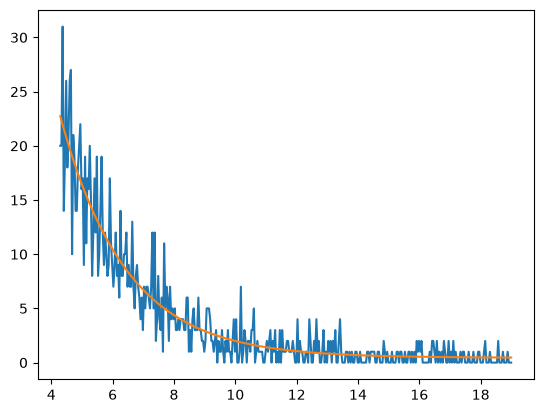

tau error: 0.10880420974947895
reduced chi squared: 1.015909488620779
2.2095437489352934


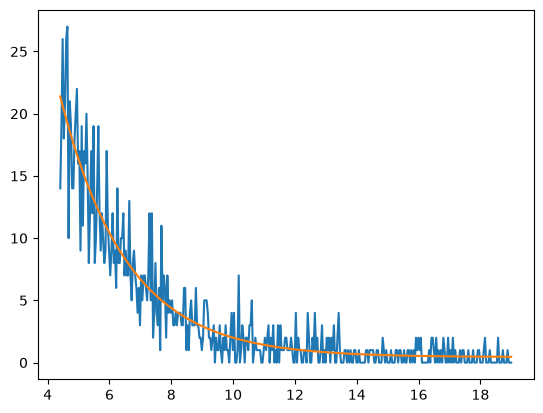

tau error: 0.11178387205837947
reduced chi squared: 1.0128192682807096
2.1913302987812213


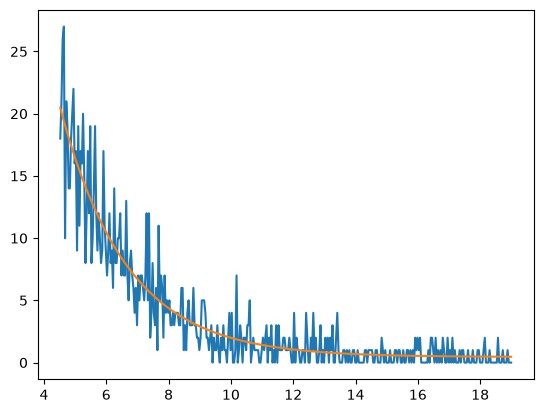

tau error: 0.11414114980634027
reduced chi squared: 1.0172750567598274
2.1842872941711526


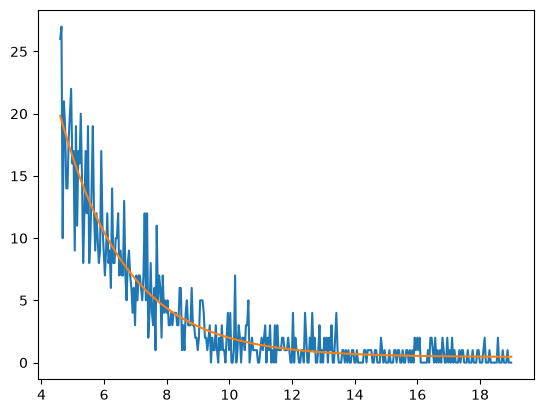

tau error: 0.1198779585727051
reduced chi squared: 1.0004315942240987
2.207596084248277


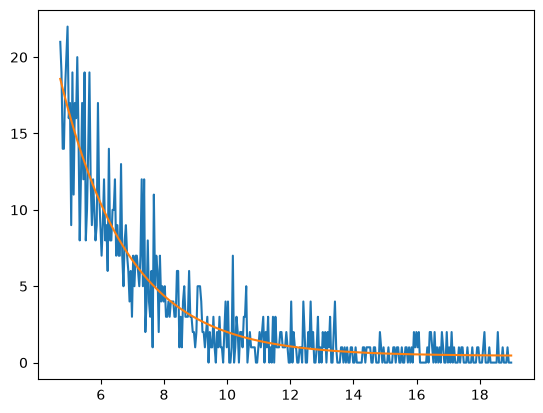

tau error: 0.12392254322237299
reduced chi squared: 1.0049294332764513
2.2234216857334808


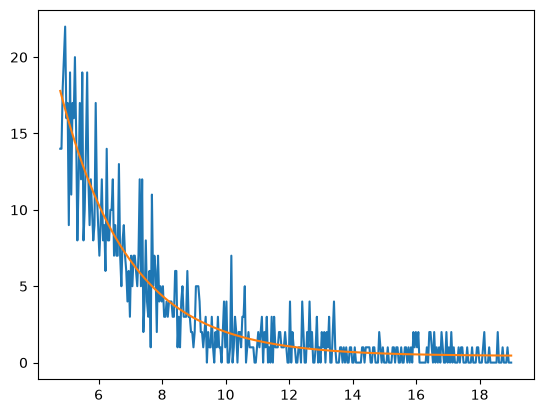

tau error: 0.12621480049608721
reduced chi squared: 1.0085073675300014
2.1883242986784586


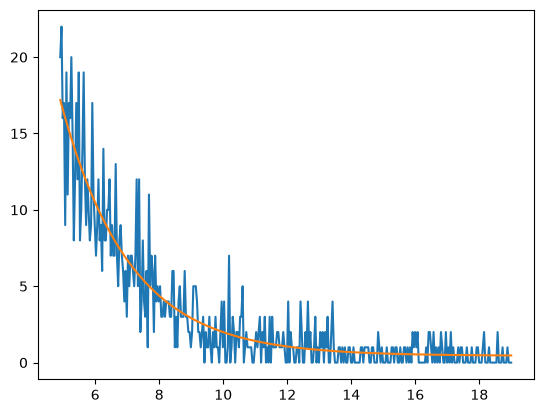

tau error: 0.1340872057457159
reduced chi squared: 1.0110438548204637
2.230964059140608


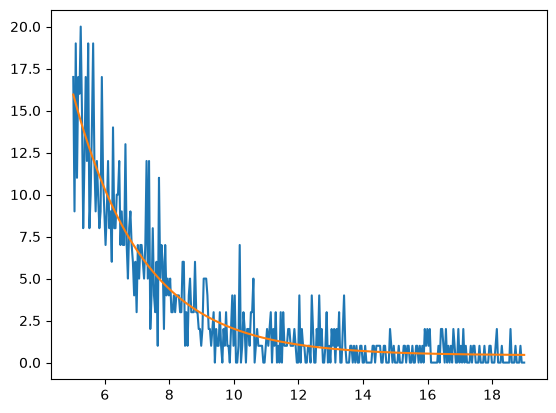

tau error: 0.13500202021491892
reduced chi squared: 1.0080962240456344
2.1978644759514943


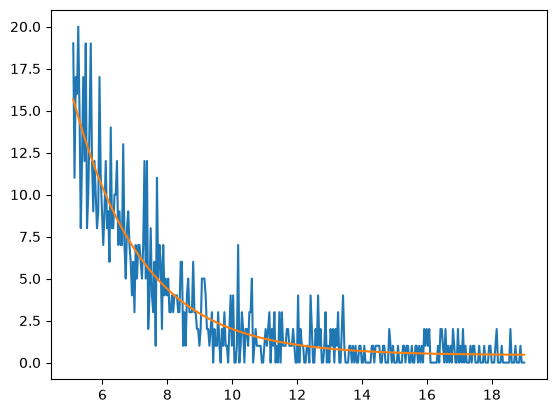

tau error: 0.14061266711845893
reduced chi squared: 1.0104369168523428
2.203155041030932


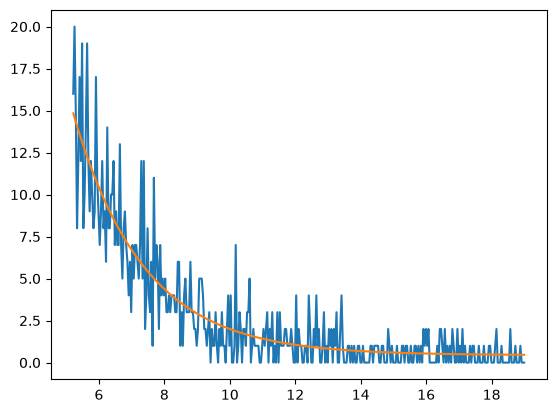

tau error: 0.14779833667860756
reduced chi squared: 1.010029021875011
2.2473191673573


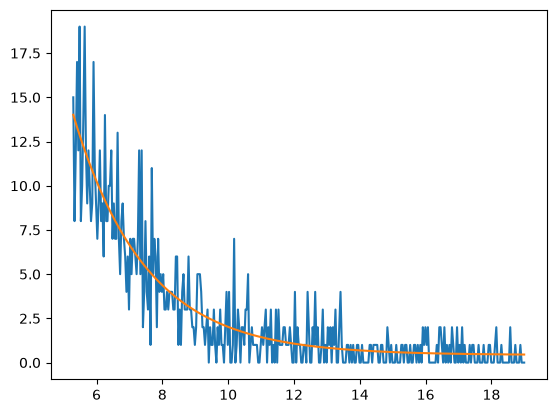

tau error: 0.14963661208781684
reduced chi squared: 1.0104099055910611
2.2013717927739256


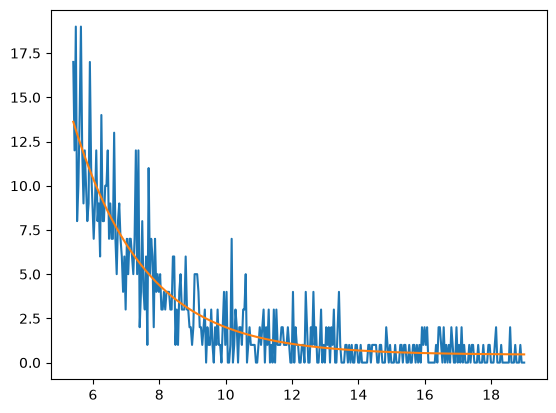

tau error: 0.16096521289150748
reduced chi squared: 1.008363914721897
2.2629777975095995


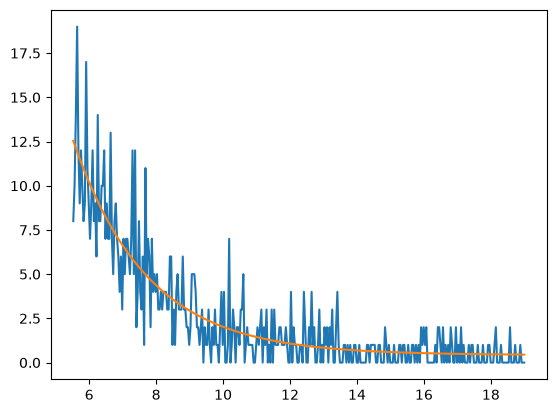

tau error: 0.1599412231162026
reduced chi squared: 1.0074228000819387
2.2063813879238707


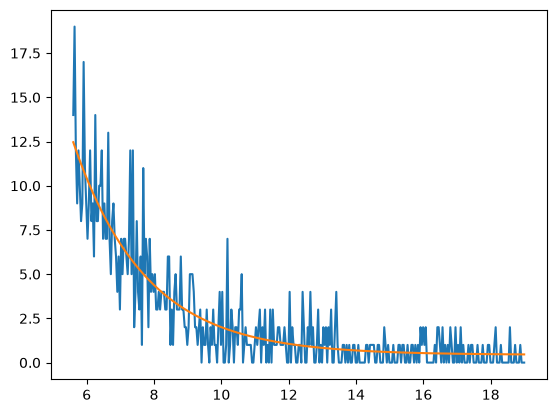

tau error: 0.17342238663697834
reduced chi squared: 1.0040078588441534
2.280657101438003


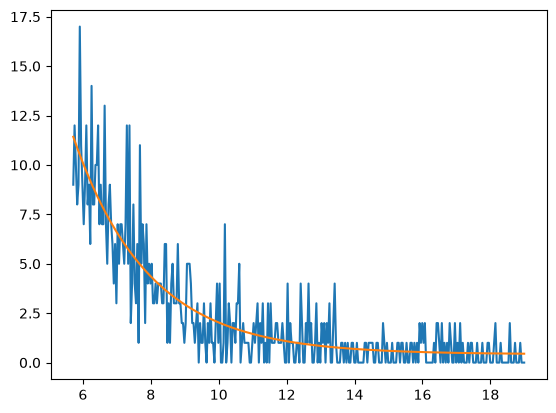

tau error: 0.17627689820432021
reduced chi squared: 1.008153288596457
2.264671859584418


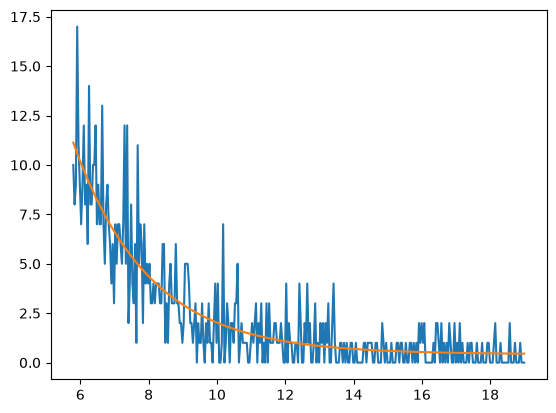

tau error: 0.1772682663882935
reduced chi squared: 1.0128377765435579
2.206169660064498


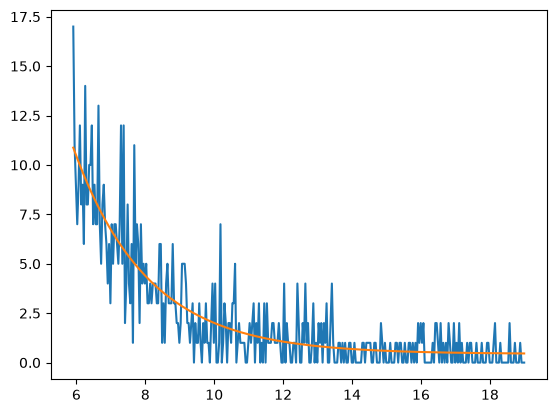

tau error: 0.19025458527261915
reduced chi squared: 1.0105823225169115
2.2614930377271256


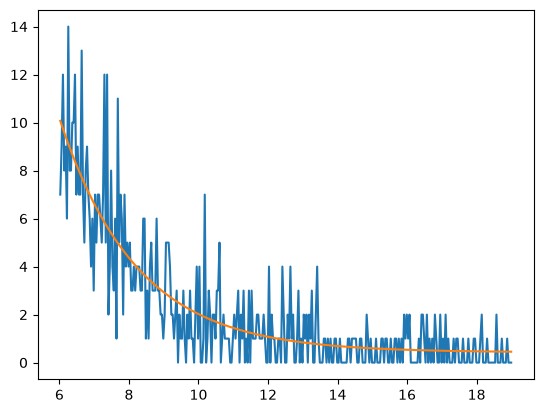

tau error: 0.19034116341271204
reduced chi squared: 1.0131724116469114
2.2165232820187946


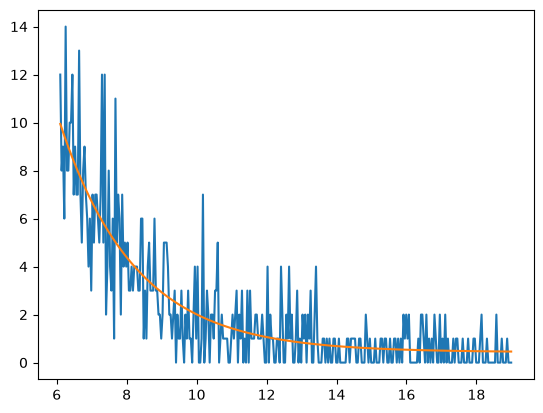

In [59]:
data_dict = get_data(data_path, TOTAL_CHANNELS)
time_cal_dict = get_data(time_cal_path_2, TOTAL_CHANNELS_2)


y_data = data_dict["data"]
y_data_rebinned = rebin_histogram(y_data, 512)

rebinned_data_dict = data_dict.copy()
rebinned_data_dict['data'] = y_data_rebinned


time_fit_param, step_array, binary_peaks = get_time_cal(rebinned_data_dict, time_cal_dict, period = 1.28, degree = 1)

m = time_fit_param[0]
b = time_fit_param[1]

start_times = np.round(np.arange(.81, 7.01, 0.1), 2)            # fit start, time after the muon (us)
end_channel = get_channel_from_time_linear(19, time_fit_param)   # TAC time

taus, errs = [], []
for s in start_times:
    start_channel = get_channel_from_time_linear(s - T_DELAY_US, time_fit_param)   # muon time -> TAC channel
    fit_y_data, _, fit_tau, _, fit_tau_err = fit_exp_dist_w_oxy_Si(y_data_rebinned, start_channel,
                                                          end_channel, time_fit_param, m)

    print(fit_tau)

    taus.append(fit_tau)
    errs.append(fit_tau_err)

    x_data = np.arange(start_channel, end_channel + 1)
    x_time = get_time_from_channel_linear(x_data, time_fit_param)

    plt.plot(x_time, y_data_rebinned[start_channel: end_channel + 1])
    plt.plot(x_time, fit_y_data)
    plt.show()
taus, errs = np.array(taus), np.array(errs)

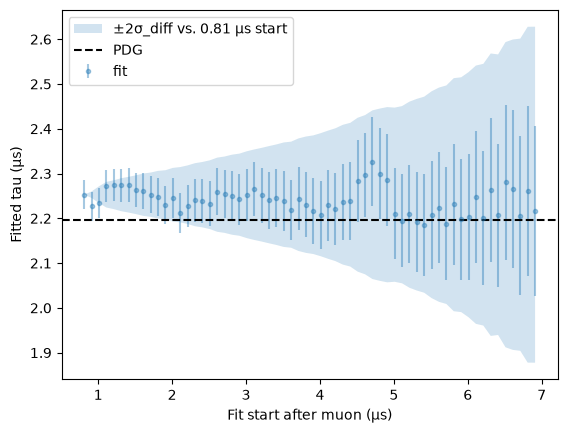

In [60]:
band = np.sqrt(np.clip(errs**2 - errs[0]**2, 0, None))   # expected scatter vs. the first start
plt.errorbar(start_times, taus, errs, fmt=".", alpha=0.4, label="fit")
plt.fill_between(start_times, taus[0] - 2*band, taus[0] + 2*band, alpha=0.2,
                 label=f"±2σ_diff vs. {start_times[0]} {mu}s start")
plt.axhline(2.1969811, color="k", ls="--", label="PDG")
plt.xlabel(f"Fit start after muon ({mu}s)")
plt.ylabel(f"Fitted tau ({mu}s)")
plt.legend()
plt.show()

# Systematic Uncertainties

In [61]:
# =============================================================================
# Systematic uncertainties on tau
#
# A) Assumption changes: refit the SAME data (same channels) with one input changed.
#    The shift in tau is not statistical noise, so it is counted directly.
# B) Stability checks: change WHICH data go into the fit (end time, background
#    freedom). These shifts include statistical scatter, so they are only counted
#    if they are significant: |shift| > 2*sigma_diff, sigma_diff = sqrt(|s1^2 - s2^2|).
# All counted sources are treated as independent and added in quadrature.
# =============================================================================

REF_START  = 1.2        # chosen fit start (us after the muon), from the start-time scan
END_TAC    = 19.0        # fit end, TAC time (us)
DELAY_ERR  = 0.050       # uncertainty of the START delay (us)  <-- set from your scope measurement
RATIO_FRAC = 0.50        # fractional uncertainty of the mu- capture amplitude ratios (Z-law)
R_O, R_SI  = 0.26, 0.19  # nominal amplitude ratios
R_NA, R_K  = 0.03, 0.035 # Na and K ratios (same Z-law estimate)
INCLUDE_NA_K = False     # True -> Na and K capture terms are part of the nominal model
TAC_INL    = 0.001       # ORTEC 566 integral nonlinearity (<= 0.1 % of full scale)
PDG_TAU    = 2.1969811

# --- calibrations, recomputed here so this cell does not depend on cell order ---
raw_counts = np.asarray(data_dict["data"])                  # 8192-channel lifetime spectrum
cal_512, steps_512, peaks_512 = get_time_cal(rebinned_data_dict, time_cal_dict, period=1.28, degree=1)
_, cal_512_cov = np.polyfit(np.where(peaks_512 > 0)[0], steps_512, 1, cov=True)
cal_8192 = get_time_cal(data_dict, get_data(time_cal_path_1, TOTAL_CHANNELS), period=1.28, degree=1)[0]

def cal_from_8192(n_bins):
    """Calibration for the spectrum rebinned to n_bins, built from the 8192-channel calibration
    (each new bin covers k old channels; its time is that of the middle old channel)."""
    k = len(raw_counts) // n_bins
    return np.array([cal_8192[0] * k, cal_8192[1] + cal_8192[0] * (k - 1) / 2])

def tau_fit(n_bins=512, cal=None, start=REF_START, end=END_TAC, scale=1.0, scale_O=1.0,
            scale_Si=1.0, na_k=None, t_delay=None, linear_bkg=False):
    """Fit tau on the spectrum rebinned to n_bins. Returns (tau, tau_err).
    scale multiplies every mu- capture ratio in the model; scale_O / scale_Si only that one.
    The start channel always uses the nominal delay, so changing t_delay changes only the
    time axis of the model, not which data are fitted."""
    na_k = INCLUDE_NA_K if na_k is None else na_k
    y = rebin_histogram(raw_counts, n_bins)
    cal = cal_512 if cal is None else np.asarray(cal)
    s_ch = get_channel_from_time_linear(start - T_DELAY_US, cal)
    e_ch = get_channel_from_time_linear(end, cal)
    out = fit_exp_dist_w_oxy_Si(y, s_ch, e_ch, cal, cal[0],
                                r_O=R_O*scale*scale_O, r_Si=R_SI*scale*scale_Si,
                                r_Na=R_NA*scale if na_k else 0.0, r_K=R_K*scale if na_k else 0.0,
                                t_delay=t_delay, linear_bkg=linear_bkg, verbose=False)
    return out[2], out[4]

tau0, stat = tau_fit()
rows = []

def add(source, tau_up, tau_down=None, counted=True, note=""):
    d_up = tau_up - tau0
    d_dn = np.nan if tau_down is None else tau_down - tau0
    rows.append(dict(source=source, up=d_up, down=d_dn,
                     syst=np.nanmax(np.abs([d_up, d_dn])), counted=counted, note=note))

# ---------------- A) assumption changes (same data) ----------------
f_up, f_dn = 1 + RATIO_FRAC, 1 - RATIO_FRAC
add("mu- ratios together", tau_fit(scale=f_up)[0], tau_fit(scale=f_dn)[0],
    note=f"all capture ratios ±{RATIO_FRAC:.0%}")
add("  O ratio alone",      tau_fit(scale_O=f_up)[0],  tau_fit(scale_O=f_dn)[0],
    counted=False, note="info: part of the row above")
add("  Si ratio alone",     tau_fit(scale_Si=f_up)[0], tau_fit(scale_Si=f_dn)[0],
    counted=False, note="info: part of the row above")
add("Na + K capture terms", tau_fit(na_k=not INCLUDE_NA_K)[0],
    note="shift when Na and K are " + ("removed from" if INCLUDE_NA_K else "added to") + " the model")
add("START delay", tau_fit(t_delay=T_DELAY_US + DELAY_ERR)[0],
                   tau_fit(t_delay=T_DELAY_US - DELAY_ERR)[0])

slope_err = np.sqrt(cal_512_cov[0, 0])
tau_slope_up = tau_fit(cal=[cal_512[0] + slope_err, cal_512[1]])[0]
tau_slope_dn = tau_fit(cal=[cal_512[0] - slope_err, cal_512[1]])[0]
tau_cal8192  = tau_fit(cal=cal_from_8192(512))[0]
d_slope = max(abs(tau_slope_up - tau0), abs(tau_slope_dn - tau0))
d_src   = abs(tau_cal8192 - tau0)
add("Time calibration", tau0 + max(d_slope, d_src),
    note=f"larger of slope error ({d_slope:.4f}) and 512-file vs 8192-file cal ({d_src:.4f})")
add("TAC nonlinearity", tau0 * (1 + TAC_INL), note="0.1 % spec")

# ---------------- B) stability checks (data or freedom change) ----------------
def check(source, tau_b, err_b, note=""):
    s_diff = np.sqrt(abs(err_b**2 - stat**2))
    signif = abs(tau_b - tau0) / s_diff if s_diff > 0 else np.inf
    add(source, tau_b, counted=signif > 2, note=f"{signif:.1f} sigma_diff; " + note)

check("Linear background", *tau_fit(linear_bkg=True), note="background allowed to slope")
check("Fit end 16 us (TAC)", *tau_fit(end=16.0))
check("Fit end 12 us (TAC)", *tau_fit(end=12.0))

# binning: same events, so tau should barely move (uses the 8192-file calibration for all three)
tau_b = {n: tau_fit(n_bins=n, cal=cal_from_8192(n))[0] for n in (256, 512, 1024)}
add("Binning 256 vs 512",  tau0 + (tau_b[256]  - tau_b[512]), counted=False, note="check only")
add("Binning 1024 vs 512", tau0 + (tau_b[1024] - tau_b[512]), counted=False, note="check only")

# ---------------- summary ----------------
syst_table = pd.DataFrame(rows).set_index("source")
total = np.sqrt((syst_table.loc[syst_table["counted"], "syst"] ** 2).sum())

with pd.option_context("display.float_format", "{:+.4f}".format, "display.max_colwidth", 80):
    display(syst_table[["up", "down", "syst", "counted", "note"]])

print(f"\ntau = {tau0:.3f} ± {stat:.3f} (stat) ± {total:.3f} (syst) {mu}s"
      f"   [start {REF_START} {mu}s after the muon; Na+K in model: {INCLUDE_NA_K}]")
print(f"PDG {PDG_TAU} {mu}s  ->  difference = {(tau0 - PDG_TAU)/np.hypot(stat, total):+.1f} sigma (stat+syst)")

,up,down,syst,counted,note
source,,,,,
mu- ratios together,+0.0520,-0.0548,+0.0548,True,all capture ratios ±50%
O ratio alone,+0.0337,-0.0348,+0.0348,False,info: part of the row above
Si ratio alone,+0.0189,-0.0193,+0.0193,False,info: part of the row above
Na + K capture terms,+0.0126,NaN,+0.0126,True,shift when Na and K are added to the model
START delay,-0.0020,+0.0021,+0.0021,True,
Time calibration,+0.0507,NaN,+0.0507,True,larger of slope error (0.0014) and 512-file vs 8192-file cal (0.0507)
TAC nonlinearity,+0.0023,NaN,+0.0023,True,0.1 % spec
Linear background,-0.0100,NaN,+0.0100,False,0.2 sigma_diff; background allowed to slope
Fit end 16 us (TAC),-0.0032,NaN,+0.0032,False,0.2 sigma_diff;



tau = 2.274 ± 0.036 (stat) ± 0.076 (syst) μs   [start 1.2 μs after the muon; Na+K in model: False]
PDG 2.1969811 μs  ->  difference = +0.9 sigma (stat+syst)


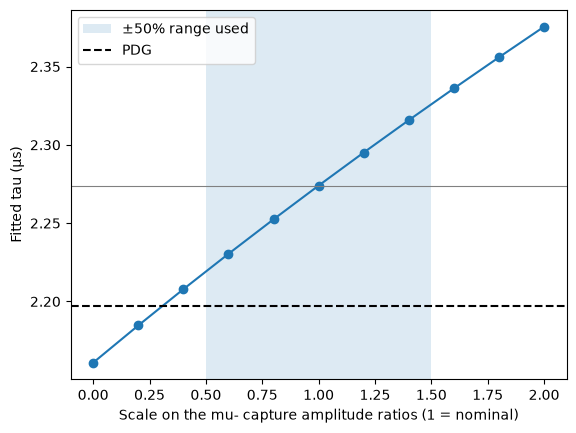

In [62]:
# How tau depends on the size of the mu- capture terms (all ratios scaled together).
# A straight line means the ±50 % end points describe the effect fully;
# scale 0 is the fit with no mu- terms at all.
scales = np.linspace(0, 2, 11)
tau_s = np.array([tau_fit(scale=s)[0] for s in scales])

plt.plot(scales, tau_s, "o-")
plt.axvspan(1 - RATIO_FRAC, 1 + RATIO_FRAC, alpha=0.15, label=f"±{RATIO_FRAC:.0%} range used")
plt.axhline(tau0, color="gray", lw=0.8)
plt.axhline(PDG_TAU, color="k", ls="--", label="PDG")
plt.xlabel("Scale on the mu- capture amplitude ratios (1 = nominal)")
plt.ylabel(f"Fitted tau ({mu}s)")
plt.legend()
plt.show()

# Combining data sets

In [63]:
# data_path_1 = r"/content/drive/MyDrive/ADVLAB/Muon-Lifetime/Data/MuonTest.Spe"
# data_path_2 = r"/content/drive/MyDrive/ADVLAB/Muon-Lifetime/Data/MuonTest2.Spe"
# data_path_3 = r"/content/drive/MyDrive/ADVLAB/Muon-Lifetime/Data/MuonTest3.Spe"

# data_paths = [data_path_1,data_path_2, data_path_3]

# all_data = None
# for path in data_paths:
#   # y_data = get_data(data_path, TOTAL_CHANNELS)["data"]
#   # y_data = np.array(y_data)

#   if all_data is None:
#     all_data = y_data
#   else:
#     all_data += y_data

# plt.plot(all_data)

# Hourly Counts

In [64]:
counts = []
counts2 = [] 
timestamps = []
timestamps2 = []
for file in sorted(os.listdir(hourly_folder_path)):
  if file.endswith(".Spe"):
    muon_data_path = os.path.join(hourly_folder_path, file)
    muon_data_dict = get_data(muon_data_path, TOTAL_CHANNELS)

    timestamp = f"{muon_data_dict['start_date']} {muon_data_dict['start_time']}"
    timestamps.append(timestamp)

    muon_data = muon_data_dict["data"]
    count = sum(muon_data)

    counts.append(count)


In [65]:
count_data = pd.DataFrame({"timestamp": timestamps, "count": counts})

#convert to datetime round to the nearest hour
count_data['timestamp'] = pd.to_datetime(count_data['timestamp'])
count_data['timestamp'] = count_data['timestamp'].dt.round('h')

met_data = pd.read_csv(r"C:\pyt\ADV-Lab\muon-lifetime\ATT.csv", parse_dates=["valid"])
met_columns = ['valid','tmpf','alti']
met_data = met_data[met_columns]

# round the valid column to the nearest hour
met_data['valid'] = met_data['valid'].dt.round('h')

merged = met_data.merge(count_data, how='inner', left_on='valid', right_on='timestamp').drop(columns = ['valid'])

print(merged.head())
print(merged.tail())

   tmpf   alti           timestamp  count
0  77.0  30.06 2026-11-12 14:00:00   5561
1  78.0  30.04 2026-11-12 15:00:00   5637
2  77.0  30.04 2026-11-12 16:00:00   5701
3  75.0  30.03 2026-11-12 17:00:00   5706
4  68.0  30.03 2026-11-12 18:00:00   5788
     tmpf   alti           timestamp  count
157  51.0  30.39 2026-11-17 09:00:00   5651
158  56.0  30.39 2026-11-17 10:00:00   5429
159  60.0  30.38 2026-11-17 11:00:00   5608
160  63.0  30.36 2026-11-17 12:00:00   5549
161  64.0  30.32 2026-11-17 13:00:00   5676


array([[<Axes: xlabel='timestamp'>],
       [<Axes: xlabel='timestamp'>],
       [<Axes: xlabel='timestamp'>]], dtype=object)

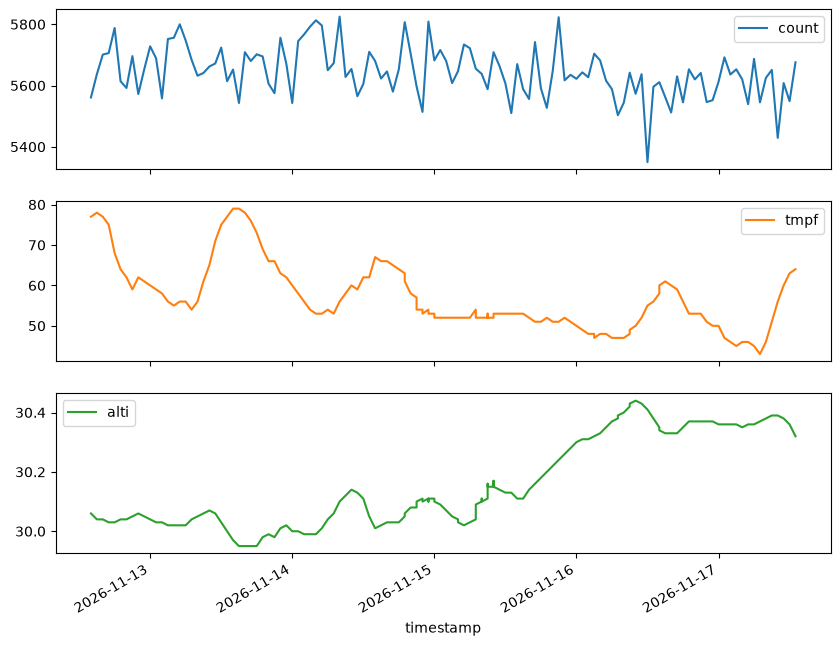

In [66]:
merged.plot(x='timestamp', y=['count', 'tmpf', 'alti'], subplots=True, layout=(3, 1), figsize=(10, 8))

In [67]:
import statsmodels.api as sm

# =============================================================================
# Barometric fit: Poisson log-link regression (GLM)
#
#   E[N_i] = t_i * exp( b0 + beta*(P_i - P_mean) [+ alpha*(T_i - T_mean)] )
#
#   N_i = counts in hourly window i,  t_i = length of window i (s)
#   log(t_i) is an "offset" (coefficient fixed at 1), so windows that are not
#   exactly 3600 s are handled exactly.
#   exp(b0) = rate (Hz) at the mean pressure
#   100*beta  = barometric coefficient (%/hPa)
#   100*alpha = temperature coefficient (%/degC), only if the temperature term is used
# =============================================================================

LAB_TZ = "America/Chicago"   # Maestro writes .Spe start times in the lab computer's local time
MET_TZ = "America/Chicago"   # time zone of the 'valid' column in the IEM CSV you downloaded
                             # (set to "UTC" if you picked UTC on the IEM download page)
                             
STATION_ELEV_M = 204.2       # Austin Camp Mabry elevation (NCEI)
INHG_TO_HPA = 33.8639


def altimeter_to_station_pressure(alti_hpa, elev_m=STATION_ELEV_M):
    """Invert the NWS altimeter-setting formula -> station pressure (hPa).
    Use this, not sea-level pressure (mslp), which mixes in temperature."""
    n = 0.190284
    return (alti_hpa**n - 8.4228807e-5 * elev_m) ** (1 / n) + 0.3


def load_met(paths, met_tz=MET_TZ):
    """Read one or more manually downloaded IEM ASOS CSVs (needs columns valid, tmpf, alti).
    Overlapping downloads are fine: duplicate times are dropped."""
    if isinstance(paths, str):
        paths = [paths]
    met = pd.concat([pd.read_csv(p, na_values=["M"]) for p in paths], ignore_index=True)

    t = pd.to_datetime(met["valid"])
    if t.dt.tz is None:
        t = t.dt.tz_localize(met_tz, ambiguous="NaT", nonexistent="shift_forward")
    met.index = pd.DatetimeIndex(t.dt.tz_convert("UTC"), name="time_utc")
    met = met[met.index.notna()]
    met = met[~met.index.duplicated(keep="last")].sort_index()

    out = pd.DataFrame(index=met.index)
    alti_hpa = pd.to_numeric(met["alti"], errors="coerce") * INHG_TO_HPA
    out["p_hPa"] = altimeter_to_station_pressure(alti_hpa)
    out["temp_C"] = (pd.to_numeric(met["tmpf"], errors="coerce") - 32) * 5 / 9
    return out


def load_hourly_counts(folder, total_channels=TOTAL_CHANNELS, lab_tz=LAB_TZ):
    """One row per .Spe file: start time (index, UTC), real/live time (s), total counts."""
    rows = []
    for f in sorted(os.listdir(folder)):
        if f.endswith(".Spe"):
            d = get_data(os.path.join(folder, f), total_channels)
            rows.append({"file": f,
                         "start_local": pd.to_datetime(f"{d['start_date']} {d['start_time']}",
                                                       format="%m/%d/%Y %H:%M:%S"),
                         "real_s": d["real_time"],
                         "live_s": d["live_time"],
                         "counts": int(np.sum(d["data"]))})
    df = pd.DataFrame(rows)
    df["start_local"] = df["start_local"].dt.tz_localize(lab_tz, ambiguous="NaT",
                                                         nonexistent="shift_forward")
    df.index = pd.DatetimeIndex(df["start_local"].dt.tz_convert("UTC"), name="start_utc")
    return df.sort_index()


def add_weather(df, met, time_col="real_s", max_gap_h=3):
    """Pressure and temperature at the MIDDLE of each counting window, linearly
    interpolated between METARs (= the hourly average for a smoothly varying field).
    Windows outside the weather data, or inside a gap > max_gap_h hours, get NaN."""
    mid = df.index + pd.to_timedelta(df[time_col].to_numpy() / 2, unit="s")
    out = df.copy()
    for col in ["p_hPa", "temp_C"]:
        s = met[col].dropna()
        x, m = s.index.asi8, mid.asi8
        val = np.interp(m, x, s.to_numpy())
        k = np.searchsorted(x, m)
        ok = (k > 0) & (k < len(x))
        gap_h = np.full(len(m), np.inf)
        gap_h[ok] = (x[k[ok]] - x[k[ok] - 1]) / 3.6e12
        val[~ok | (gap_h > max_gap_h)] = np.nan
        out[col] = val
    return out


def design_matrix(df, p_col="p_hPa", extra_cols=()):
    """Columns: constant, centered pressure, and any extra centered regressors."""
    X = pd.DataFrame({"const": 1.0, "dP": df[p_col] - df[p_col].mean()}, index=df.index)
    for c in extra_cols:
        X["d_" + c] = df[c] - df[c].mean()
    return X


def fit_glm(df, count_col="counts", time_col="real_s", p_col="p_hPa", extra_cols=()):
    """Poisson GLM, log link, offset log(window length). Returns (result, Pearson chi2/dof)."""
    X = design_matrix(df, p_col, extra_cols)
    model = sm.GLM(df[count_col], X, family=sm.families.Poisson(),
                   offset=np.log(df[time_col]))
    res = model.fit()
    chi2_dof = res.pearson_chi2 / res.df_resid
    return res, chi2_dof


def report(df, res, chi2_dof, count_col="counts", time_col="real_s", p_col="p_hPa"):
    b, e = res.params, res.bse
    # if chi2/dof > 1 there is extra (non-Poisson) scatter: inflate the errors by sqrt(chi2/dof)
    es = e * np.sqrt(max(1.0, chi2_dof))
    rate = df[count_col] / df[time_col]
    t_loc = df.index.tz_convert(LAB_TZ)

    print(f"windows used      : {len(df)}   ({t_loc.min():%m/%d %H:%M} to {t_loc.max():%m/%d %H:%M} local)")
    print(f"pressure range    : {df[p_col].min():.1f} - {df[p_col].max():.1f} hPa   (sd {df[p_col].std():.2f} hPa)")
    print(f"rate at mean P    : {np.exp(b['const']):.4f} Hz")
    print(f"beta (pressure)   : {100*b['dP']:+.4f} ± {100*e['dP']:.4f} %/hPa"
          f"   [chi2-scaled: ± {100*es['dP']:.4f}]")
    for name in b.index[2:]:
        unit = "%/degC" if "temp" in name else "%/unit"
        print(f"{name + ' coef':18s}: {100*b[name]:+.4f} ± {100*e[name]:.4f} {unit}"
              f"   [chi2-scaled: ± {100*es[name]:.4f}]")
        cov = res.cov_params()
        r = cov.loc["dP", name] / np.sqrt(cov.loc["dP", "dP"] * cov.loc[name, name])
        print(f"{'corr(beta, ' + name + ')':18s}: {r:+.2f}   (near ±1 = pressure and temp can't be separated yet)")
    print(f"Pearson chi2/dof  : {chi2_dof:.3f}   (dof = {int(res.df_resid)}; ~1 = pure counting noise)")
    print(f"r(rate, pressure) : {np.corrcoef(rate, df[p_col])[0, 1]:+.3f}   (descriptive only; beta is the result)")


def plot_fit(df, res, count_col="counts", time_col="real_s", p_col="p_hPa"):
    b = res.params
    rate = df[count_col] / df[time_col]
    err = np.sqrt(df[count_col]) / df[time_col]
    mu = res.fittedvalues
    pull = (df[count_col] - mu) / np.sqrt(mu)
    t_loc = df.index.tz_convert(LAB_TZ).tz_localize(None)

    # remove the fitted effect of any extra regressors so the top panel shows pressure alone
    extra_names = list(b.index[2:])
    if extra_names:
        X = design_matrix(df, p_col, [c[2:] for c in extra_names])
        corr = np.exp(-(X[extra_names] @ b[extra_names]))
    else:
        corr = 1.0

    fig, ax = plt.subplots(3, 1, figsize=(8, 11))

    ax[0].errorbar(df[p_col], rate * corr, err * corr, fmt="o", ms=3, alpha=0.5,
                   label="data" + (" (corrected to mean temp)" if extra_names else ""))
    pp = np.linspace(df[p_col].min(), df[p_col].max(), 100)
    ax[0].plot(pp, np.exp(b["const"] + b["dP"] * (pp - df[p_col].mean())), "r-",
               label=f"fit: beta = {100*b['dP']:+.3f} %/hPa")
    ax[0].set(xlabel="Station pressure (hPa)", ylabel="Rate (Hz)")
    ax[0].legend()

    ax[1].errorbar(t_loc, rate, err, fmt=".", alpha=0.4, label="rate")
    ax[1].plot(t_loc, mu / df[time_col], "r-", lw=1, label="fit")
    ax[1].set_ylabel("Rate (Hz)")
    ax[1].legend(loc="upper left")
    axp = ax[1].twinx()
    axp.plot(t_loc, df[p_col], "g-", lw=1)
    axp.set_ylabel("Station pressure (hPa)", color="g")

    ax[2].plot(t_loc, pull, ".")
    ax[2].axhline(0, color="k", lw=0.8)
    ax[2].set(xlabel=f"Window start ({LAB_TZ})", ylabel="Residual (sigma)")

    for a in ax[1:]:
        a.tick_params(axis="x", labelrotation=30)
    fig.tight_layout()
    plt.show()

In [68]:
import io
import requests

# =============================================================================
# Download Camp Mabry (ATT) weather reports from the Iowa Environmental Mesonet
# and save them to the file the fitting cell reads (MET_CSV_PATHS in the next cell).
#
# The whole date range is downloaded again on every run. The old file is replaced
# only if the new download looks right, so a failed request never wipes it.
# Timestamps are written in MET_TZ (set in the functions cell), the time zone
# load_met() assumes when it reads the file.
# =============================================================================

MET_CSV_PATH = r"C:\pyt\ADV-Lab\muon-lifetime\ATT.csv"   # same file as MET_CSV_PATHS in the fitting cell
STATION      = "ATT"     # Austin Camp Mabry  (use "AUS" for Bergstrom, saved to a different file)
MET_START    = None      # 'YYYY-MM-DD'; None -> one day before the first hourly .Spe file
MET_END      = None      # 'YYYY-MM-DD', inclusive; None -> today
IEM_URL      = "https://mesonet.agron.iastate.edu/cgi-bin/request/asos.py"


def download_asos(station, start, end, tz):
    """Routine (hourly) + special reports from start to end (dates, both inclusive), as CSV text."""
    s = pd.Timestamp(start)
    e = pd.Timestamp(end) + pd.Timedelta(days=1)             # IEM's end date is exclusive
    params = {"station": station, "data": ["tmpf", "alti", "mslp"],
              "year1": s.year, "month1": s.month, "day1": s.day,
              "year2": e.year, "month2": e.month, "day2": e.day,
              "tz": tz, "format": "onlycomma", "latlon": "no", "elev": "no",
              "missing": "M", "trace": "T", "direct": "no",
              "report_type": [3, 4]}                          # 3 = routine, 4 = specials
    r = requests.get(IEM_URL, params=params, timeout=180)
    r.raise_for_status()
    if len(r.text.strip().splitlines()) < 2:                  # no rows: retry with the server's default report types
        params.pop("report_type")
        r = requests.get(IEM_URL, params=params, timeout=180)
        r.raise_for_status()
    return r.text


# ---------------- date range ----------------
iem_tz = "Etc/UTC" if MET_TZ.upper() in ("UTC", "ETC/UTC") else MET_TZ
if MET_START is not None:
    start = MET_START
else:
    first_window = load_hourly_counts(hourly_folder_path).index.min()
    start = (first_window.tz_convert(iem_tz) - pd.Timedelta(days=1)).strftime("%Y-%m-%d")
end = MET_END if MET_END is not None else pd.Timestamp.now(tz=iem_tz).strftime("%Y-%m-%d")

# ---------------- download, check, save ----------------
csv_text = download_asos(STATION, start, end, iem_tz)
new = pd.read_csv(io.StringIO(csv_text), na_values=["M"])
if new.empty or not {"valid", "tmpf", "alti"}.issubset(new.columns):
    raise RuntimeError("Download looks wrong, so the old file was kept. Start of the reply:\n"
                       + csv_text[:300])

os.makedirs(os.path.dirname(MET_CSV_PATH), exist_ok=True)
tmp_path = MET_CSV_PATH + ".tmp"
with open(tmp_path, "w", newline="") as f:
    f.write(csv_text)
os.replace(tmp_path, MET_CSV_PATH)                            # swap in the new file in one step

t = pd.to_datetime(new["valid"])
print(f"saved {len(new)} reports for {STATION} to {MET_CSV_PATH}")
print(f"  {t.min():%Y-%m-%d %H:%M} to {t.max():%Y-%m-%d %H:%M}  ({iem_tz})")
print(f"  missing: alti {new['alti'].isna().sum()},  tmpf {new['tmpf'].isna().sum()}")

saved 234 reports for ATT to C:\pyt\ADV-Lab\muon-lifetime\ATT.csv
  2026-11-11 00:51 to 2026-11-18 13:51  (America/Chicago)
  missing: alti 0,  tmpf 0


120 of 120 hourly windows matched to Camp Mabry weather

windows used      : 120   (11/12 13:31 to 11/17 12:31 local)
pressure range    : 990.2 - 1006.4 hPa   (sd 5.07 hPa)
rate at mean P    : 1.5681 Hz
beta (pressure)   : -0.1249 ± 0.0241 %/hPa   [chi2-scaled: ± 0.0241]
Pearson chi2/dof  : 0.980   (dof = 118; ~1 = pure counting noise)
r(rate, pressure) : -0.434   (descriptive only; beta is the result)


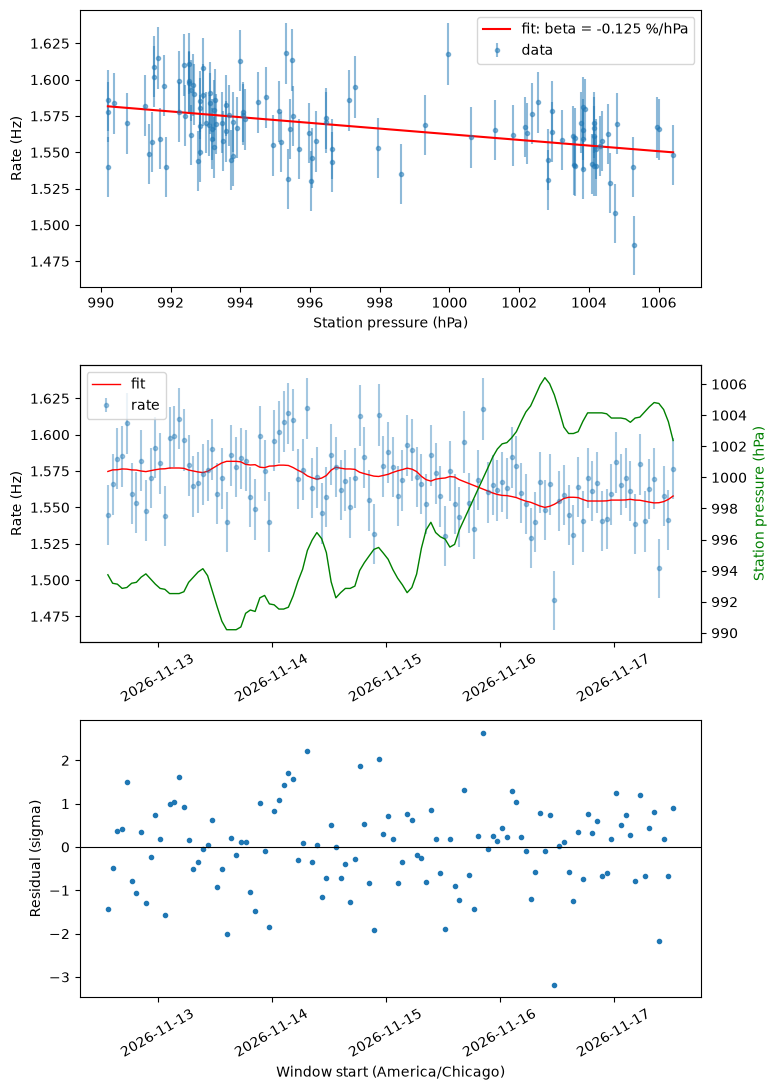

In [69]:
# ---------------- inputs ----------------
# IEM ASOS CSVs for station ATT (columns valid, tmpf, alti). Add each new manual
# download to this list; overlapping time ranges are fine.
MET_CSV_PATHS = [r"C:\pyt\ADV-Lab\muon-lifetime\ATT.csv"]

USE_TEMP = False      # True -> add surface temperature (degC) as a second regressor
TIME_COL = "real_s"   # exposure per window; "live_s" uses MCA live time instead

# ---------------- one row per hourly .Spe file, with weather at mid-window ----------------
met = load_met(MET_CSV_PATHS)
df = add_weather(load_hourly_counts(hourly_folder_path), met, time_col=TIME_COL)

n_all = len(df)
need = ["p_hPa"] + (["temp_C"] if USE_TEMP else [])
df = df.dropna(subset=need)
df = df[df[TIME_COL] > 0]
print(f"{len(df)} of {n_all} hourly windows matched to Camp Mabry weather\n")

# ---------------- fit ----------------
extra = ["temp_C"] if USE_TEMP else []
res, chi2_dof = fit_glm(df, time_col=TIME_COL, extra_cols=extra)
report(df, res, chi2_dof, time_col=TIME_COL)

if USE_TEMP:
    # does the temperature term improve the fit? likelihood-ratio test vs. pressure only
    from scipy.stats import chi2 as chi2_dist
    res_p, _ = fit_glm(df, time_col=TIME_COL)
    d_dev = res_p.deviance - res.deviance
    print(f"\npressure-only beta: {100*res_p.params['dP']:+.4f} ± {100*res_p.bse['dP']:.4f} %/hPa")
    print(f"temp term: deviance drop = {d_dev:.2f}, p = {chi2_dist.sf(d_dev, 1):.3f}"
          "   (p < 0.05 -> temperature term is supported by the data)")

plot_fit(df, res, time_col=TIME_COL)

120 windows with T_mw;  T_mw range 251.65 - 254.48 K  (sd 0.88 K)

OLS on ln(rate): beta = -0.1249 ± 0.0239 %/hPa
pressure only        : beta = -0.1249 ± 0.0241 %/hPa
T_mw vs pressure     : b = -0.052 K/hPa
expected bias, alpha*b = +0.0103 %/hPa  (0.43 x the statistical error of beta)

free alpha           : beta = -0.1308 ± 0.0253 %/hPa,  alpha = -0.114 ± 0.145 %/K  (literature about -0.2)
alpha fixed -0.2 %/K : beta = -0.1353 ± 0.0241 (stat) ± 0.0052 (alpha ±50%) %/hPa


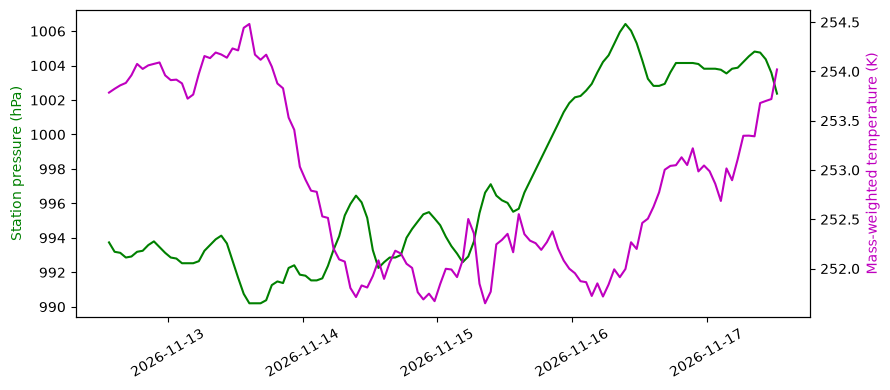

In [70]:
import requests

# =============================================================================
# Atmospheric (mass-weighted) temperature from upper-air data
#
# Source: Open-Meteo Historical Forecast API -> hourly model analyses (GFS-based)
#         of temperature on 19 pressure levels, 1000 to 30 hPa. Free, no key.
# T_mw = sum(T_i * dp_i) / sum(dp_i): each level stands for the air layer between
#        the midpoints to its neighbours, from the ground (station pressure) up to 0 hPa.
# =============================================================================

LAT, LON  = 30.2887, -97.7366   # PMA building, UT Austin
LEVELS    = [1000, 975, 950, 925, 900, 850, 800, 700, 600, 500,
             400, 300, 250, 200, 150, 100, 70, 50, 30]          # hPa
ALPHA_LIT = -0.0020             # literature temperature coefficient, about -0.2 %/K of T_mw
ALPHA_FRAC = 0.5                # uncertainty used for ALPHA_LIT in the fixed-alpha fit


def fetch_upper_air(start, end, lat=LAT, lon=LON):
    """Hourly temperatures (K) on pressure levels, UTC index. start/end: 'YYYY-MM-DD', inclusive."""
    params = {"latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
              "hourly": ",".join(f"temperature_{p}hPa" for p in LEVELS), "timezone": "UTC"}
    r = requests.get("https://historical-forecast-api.open-meteo.com/v1/forecast",
                     params=params, timeout=120)
    r.raise_for_status()
    h = r.json()["hourly"]
    idx = pd.DatetimeIndex(pd.to_datetime(h["time"]), name="time_utc").tz_localize("UTC")
    ua = pd.DataFrame({p: h[f"temperature_{p}hPa"] for p in LEVELS}, index=idx).astype(float)
    return ua + 273.15                                       # degC -> K


def mass_weighted_temperature(T_levels, p_surface_hPa):
    """T_mw for each row of T_levels (columns = LEVELS, in K). Levels below the ground
    (pressure above the station pressure) are left out; the lowest level above the
    ground covers the air down to the surface."""
    p = np.array(LEVELS, float)
    T = T_levels[LEVELS].to_numpy(float)
    ps = np.asarray(p_surface_hPa, float)[:, None]
    mids = (p[:-1] + p[1:]) / 2
    bottom = np.broadcast_to(np.concatenate(([np.inf], mids)), T.shape).copy()
    top = np.concatenate((mids, [0.0]))
    above = p[None, :] <= ps
    first = np.where(above.any(axis=1), above.argmax(axis=1), 0)
    bottom[np.arange(len(T)), first] = ps[:, 0]
    dp = np.clip(np.minimum(bottom, ps) - top, 0, None) * above
    return (T * dp).sum(axis=1) / dp.sum(axis=1)


def add_upper_air(df, ua, time_col="real_s"):
    """T_mw at the middle of each counting window (level temperatures interpolated in time)."""
    mid = df.index + pd.to_timedelta(df[time_col].to_numpy() / 2, unit="s")
    T_mid = pd.DataFrame({p: np.interp(mid.asi8, ua.index.asi8, ua[p].to_numpy(),
                                       left=np.nan, right=np.nan) for p in LEVELS},
                         index=df.index)
    out = df.copy()
    out["temp_mw"] = mass_weighted_temperature(T_mid, df["p_hPa"])
    return out


# ---------------- get the data and line it up with the counting windows ----------------
ua = fetch_upper_air(f"{df.index.min():%Y-%m-%d}", f"{df.index.max():%Y-%m-%d}")
dfu = add_upper_air(df, ua, time_col=TIME_COL).dropna(subset=["p_hPa", "temp_mw"])
print(f"{len(dfu)} windows with T_mw;  T_mw range {dfu['temp_mw'].min():.2f} - "
      f"{dfu['temp_mw'].max():.2f} K  (sd {dfu['temp_mw'].std():.2f} K)\n")

ols = sm.OLS(np.log(dfu["counts"] / dfu[TIME_COL]), design_matrix(dfu)).fit()
print(f"OLS on ln(rate): beta = {100*ols.params['dP']:+.4f} ± {100*ols.bse['dP']:.4f} %/hPa")

# ---------------- 1) would leaving T_mw out bias beta? ----------------
res_p, _ = fit_glm(dfu, time_col=TIME_COL)                        # pressure only
b_TP = np.polyfit(dfu["p_hPa"], dfu["temp_mw"], 1)[0]             # K per hPa over this run
bias = ALPHA_LIT * b_TP
print(f"pressure only        : beta = {100*res_p.params['dP']:+.4f} ± {100*res_p.bse['dP']:.4f} %/hPa")
print(f"T_mw vs pressure     : b = {b_TP:+.3f} K/hPa")
print(f"expected bias, alpha*b = {100*bias:+.4f} %/hPa  "
      f"({abs(bias)/res_p.bse['dP']:.2f} x the statistical error of beta)\n")

# ---------------- 2) alpha fitted freely ----------------
res_free, chi2_free = fit_glm(dfu, time_col=TIME_COL, extra_cols=["temp_mw"])
a, a_err = res_free.params["d_temp_mw"], res_free.bse["d_temp_mw"]
print(f"free alpha           : beta = {100*res_free.params['dP']:+.4f} ± {100*res_free.bse['dP']:.4f} %/hPa,"
      f"  alpha = {100*a:+.3f} ± {100*a_err:.3f} %/K  (literature about {100*ALPHA_LIT:+.1f})")

# ---------------- 3) alpha fixed at the literature value (use while alpha is poorly measured) ----------------
def beta_fixed_alpha(alpha):
    X = design_matrix(dfu)
    off = np.log(dfu[TIME_COL]) + alpha * (dfu["temp_mw"] - dfu["temp_mw"].mean())
    r = sm.GLM(dfu["counts"], X, family=sm.families.Poisson(), offset=off).fit()
    return r.params["dP"], r.bse["dP"]

beta_fix, beta_fix_err = beta_fixed_alpha(ALPHA_LIT)
d_alpha = max(abs(beta_fixed_alpha(ALPHA_LIT * (1 + ALPHA_FRAC))[0] - beta_fix),
              abs(beta_fixed_alpha(ALPHA_LIT * (1 - ALPHA_FRAC))[0] - beta_fix))
print(f"alpha fixed {100*ALPHA_LIT:+.1f} %/K : beta = {100*beta_fix:+.4f} ± {100*beta_fix_err:.4f} (stat)"
      f" ± {100*d_alpha:.4f} (alpha ±{ALPHA_FRAC:.0%}) %/hPa")

# ---------------- plot: pressure and T_mw over the run ----------------
t_loc = dfu.index.tz_convert(LAB_TZ).tz_localize(None)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t_loc, dfu["p_hPa"], "g-", label="station pressure")
ax.set_ylabel("Station pressure (hPa)", color="g")
ax2 = ax.twinx()
ax2.plot(t_loc, dfu["temp_mw"], "m-", label="T_mw")
ax2.set_ylabel("Mass-weighted temperature (K)", color="m")
ax.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
plt.show()